# TRACE-X v4 — Native-Resolution, Forensic-Channel Image Manipulation Localization

**What v3 told us:** the pipeline and split were sound (zero source overlap), but the model was weak (AUC ≈ 0.69, median IoU = 0). v4 changes the *model and training setup* to address the most likely causes. It does **not** guarantee better numbers; compare against the v3 table in section 12.

| # | v3 problem | v4 change |
|---|---|---|
| 1 | Letterbox resizing to 320×320 destroys pixel-level traces | **No resizing.** Train on native-resolution 256×256 crops (8-aligned so JPEG block grids are preserved); infer on the full-resolution image |
| 2 | RGB-only input | **7-channel input:** RGB + ELA + 3 fixed SRM noise-residual filters (individually switchable for ablations) |
| 3 | Weak image-level detector (max of probability map) | **Multi-task:** segmentation head + image-level classification head; the better score source is chosen on validation |
| 4 | Checkpoint picked by validation loss; pos-weight 5 over-predicts | **Checkpoint picked by validation AUC + Dice**; positive weight lowered to 2; one-cycle LR schedule; early stopping |
| 5 | Only 1,200 images/class used | **All training rows** used via class-balanced sampling (random crops, tamper-biased) |
| 6 | CASIA format confound (authentic mostly JPEG, tampered often TIF) | **Diagnostic** of the confound, optional **format normalisation** (everything re-saved as JPEG), and **per-format test breakdown** |
| 7 | Single operating point | Image threshold chosen two ways on validation (balanced accuracy, and FPR ≤ 10 %); localization reported ungated **and** gated by the image decision |

**Split:** identical strict source-component logic and seeds as v3, with the same 250/250 val/test caps, so the test set should match v3's for a fair comparison (check section 5).

## Before running
- **Settings → Accelerator → GPU (T4)**. Internet must be on for the pretrained ResNet-18 weights (falls back to random init otherwise).
- Expect roughly 1.5–3 min per epoch on a T4; the default budget stops training after `TIME_BUDGET_MIN` minutes.
- Ablations: flip `USE_ELA`, `USE_SRM`, `NORMALIZE_FORMAT` in section 1 and rerun from the top (use a new `OUTPUT_DIR` suffix to keep results apart).

**Research honesty:** all numbers come from the executed notebook. A wrong guess about what helps is a legitimate result; report it as is. This is a screening aid, not forensic proof or an editing-history reconstruction.


## 1. Environment and configuration


In [6]:
import os, re, io, json, math, time, random, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

warnings.filterwarnings("ignore", category=UserWarning)
Image.MAX_IMAGE_PIXELS = None

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IS_KAGGLE = Path("/kaggle/input").exists()
INPUT_ROOT = Path("/kaggle/input") if IS_KAGGLE else Path("./data")
OUTPUT_DIR = Path("/kaggle/working/trace_x_outputs_v4") if IS_KAGGLE else Path("./trace_x_outputs_v4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Input representation ----------------
CROP_SIZE = 256            # native-resolution training crop (no resizing anywhere)
NORMALIZE_FORMAT = True    # re-save every image as JPEG so file format cannot be a shortcut
NORMALIZE_QUALITY = 95
ELA_QUALITY = 80 if NORMALIZE_FORMAT else 90   # must differ from NORMALIZE_QUALITY or ELA is ~0
ELA_SCALE = 15.0
USE_ELA = True             # ablation switches (channels are zeroed, architecture unchanged)
USE_SRM = True

# ---------------- Training ----------------
BATCH_SIZE = 16
EPOCHS = 24
SAMPLES_PER_EPOCH = 4800   # class-balanced random draws per epoch
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
POS_WEIGHT = 2.0
DICE_WEIGHT = 0.5
CLS_WEIGHT = 0.5
POSITIVE_CROP_PROB = 0.8   # probability a manipulated-image crop is centred on the tampered region
MIN_POS_PIXELS = 32        # a crop counts as "manipulated" only if it holds at least this many mask pixels
PATIENCE = 6
TIME_BUDGET_MIN = 120
USE_PRETRAINED_ENCODER = True
RESUME_TRAINING = False

# ---------------- Evaluation split sizes (same as v3 for comparability) ----------------
MAX_VAL_PER_CLASS = 250
MAX_TEST_PER_CLASS = 250
MAX_AUTHENTIC_PREDICTED_AREA = 0.05
NUM_WORKERS = 4 if IS_KAGGLE else 0
USE_AMP = DEVICE.type == "cuda"

print("PyTorch:", torch.__version__, "| Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
elif IS_KAGGLE:
    print("WARNING: CPU only. Enable Settings -> Accelerator -> GPU before training.")
print("Output directory:", OUTPUT_DIR)


PyTorch: 2.11.0+cu128 | Device: cuda
GPU: Tesla T4
Output directory: /kaggle/working/trace_x_outputs_v4


## 2. Locate CASIA inside Kaggle (no local download/upload)


In [7]:
CASIA_KAGGLE_SLUG = "divg07/casia-20-image-tampering-detection-dataset"

def find_existing_casia_root(input_root):
    if not input_root.exists():
        return None
    exact = input_root / "datasets" / "divg07" / "casia-20-image-tampering-detection-dataset"
    if exact.exists() and exact.is_dir():
        return exact
    candidates = []
    for p in list(input_root.iterdir()) + list(input_root.glob("datasets/*/*")):
        if p.is_dir() and "casia" in p.name.lower() and "groundtruth" not in p.name.lower():
            candidates.append(p)
    return sorted(candidates, key=lambda p: (len(p.parts), str(p).lower()))[0] if candidates else None

DATASET_ROOT = find_existing_casia_root(INPUT_ROOT)
if DATASET_ROOT is None:
    try:
        import kagglehub
        print("CASIA not found in mounted paths. Trying KaggleHub inside this runtime...")
        DATASET_ROOT = Path(kagglehub.dataset_download(CASIA_KAGGLE_SLUG))
    except Exception as exc:
        raise RuntimeError("CASIA could not be located or fetched. Use Add Input to attach it, then rerun.") from exc
DATASET_ROOT = Path(DATASET_ROOT)
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset path does not exist: {DATASET_ROOT}")
print("Using dataset root:", DATASET_ROOT)


Using dataset root: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset


## 3. Inventory and exact image–mask pairing (scans once, no mask decoding)


In [8]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SOURCE_TOKEN_RE = re.compile(r"(?:ani|cha|ind|nat|arc|txt|sec|pla|art|xxx)[_-]?\d{5}", re.I)

def path_is_groundtruth(path):
    parts = [x.lower().replace(" ", "_") for x in Path(path).parts]
    return any("groundtruth" in x or "ground_truth" in x or x in {"masks", "mask"} for x in parts[:-1])

def is_explicit_mask(path):
    stem = Path(path).stem.lower()
    return (path_is_groundtruth(path) or stem.endswith(("_gt", "_mask", "_groundtruth", "_ground_truth")))

def classify_image(path):
    p = Path(path); stem = p.stem.lower()
    parents = [x.lower().replace(" ", "_") for x in p.parts[:-1]]
    if is_explicit_mask(p):
        return "mask"
    if re.match(r"^au[_-]", stem) or any(x in {"au", "authentic", "authentic_images", "original", "originals", "real"} for x in parents):
        return "authentic"
    if re.match(r"^tp[_-]", stem) or any(x in {"tp", "tampered", "tampered_images", "spliced", "forged", "fake"} for x in parents):
        return "manipulated"
    return "unknown"

def mask_key(path):
    stem = Path(path).stem.lower()
    for suffix in ("_ground_truth", "_groundtruth", "_mask", "_gt"):
        if stem.endswith(suffix):
            return stem[:-len(suffix)]
    return stem

def source_tokens(path):
    # ani_00001, ani-00001 and ani00001 all canonicalise to ani00001
    return sorted(set(t.lower().replace("_", "").replace("-", "") for t in SOURCE_TOKEN_RE.findall(Path(path).stem)))

all_image_files = sorted({p.resolve() for p in DATASET_ROOT.rglob("*")
                          if p.is_file() and p.suffix.lower() in IMAGE_EXTS})
print(f"Image-like files under dataset root: {len(all_image_files):,}")

mask_paths, classified_images, unknown_count = [], [], 0
for p in tqdm(all_image_files, desc="Classifying"):
    c = classify_image(p)
    if c == "mask": mask_paths.append(p)
    elif c in {"authentic", "manipulated"}: classified_images.append((p, c))
    else: unknown_count += 1

masks_by_key = defaultdict(list)
for p in mask_paths:
    masks_by_key[mask_key(p)].append(p)

records, no_mask, ambiguous = [], 0, 0
for image_path, cls_name in tqdm(classified_images, desc="Pairing"):
    if cls_name == "authentic":
        records.append({"image_path": str(image_path), "mask_path": "", "label": 0,
                        "class_name": "authentic", "sample_id": image_path.stem,
                        "source_tokens": source_tokens(image_path)})
        continue
    matches = masks_by_key.get(image_path.stem.lower(), [])
    if len(matches) == 0: no_mask += 1; continue
    if len(matches) > 1: ambiguous += 1; continue
    records.append({"image_path": str(image_path), "mask_path": str(matches[0]), "label": 1,
                    "class_name": "manipulated", "sample_id": image_path.stem,
                    "source_tokens": source_tokens(image_path)})

data = pd.DataFrame(records).drop_duplicates(subset=["image_path"]).reset_index(drop=True)
data["ext"] = data.image_path.map(lambda p: Path(p).suffix.lower())
if data.empty or data.label.nunique() < 2:
    raise RuntimeError("Need both authentic and mask-paired manipulated samples.")
print(f"\nExplicit masks: {len(mask_paths)} | manipulated without mask: {no_mask} | ambiguous: {ambiguous} | unknown skipped: {unknown_count}")
print("Usable rows:", len(data))
display(data.groupby("class_name").size().rename("count").to_frame())


Image-like files under dataset root: 17,737


Classifying:   0%|          | 0/17737 [00:00<?, ?it/s]

Pairing:   0%|          | 0/12614 [00:00<?, ?it/s]


Explicit masks: 5123 | manipulated without mask: 142 | ambiguous: 0 | unknown skipped: 0
Usable rows: 12472


,count
class_name,
authentic,7491
manipulated,4981


## 4. Diagnose the CASIA file-format confound and audit masks

If tampered images are mostly TIFF and authentic images mostly JPEG, a model can score well by detecting the *format* instead of the manipulation. The numbers below show how strong that shortcut is on this copy of CASIA.


ext,.bmp,.jpg,.tif
class_name,,,
authentic,54,7437,0
manipulated,0,2004,2977


Shortcut rule 'TIFF => manipulated' on all rows: accuracy = 0.8393 | balanced accuracy = 0.7988
If this shortcut is far above 0.5, format normalisation (NORMALIZE_FORMAT) matters.



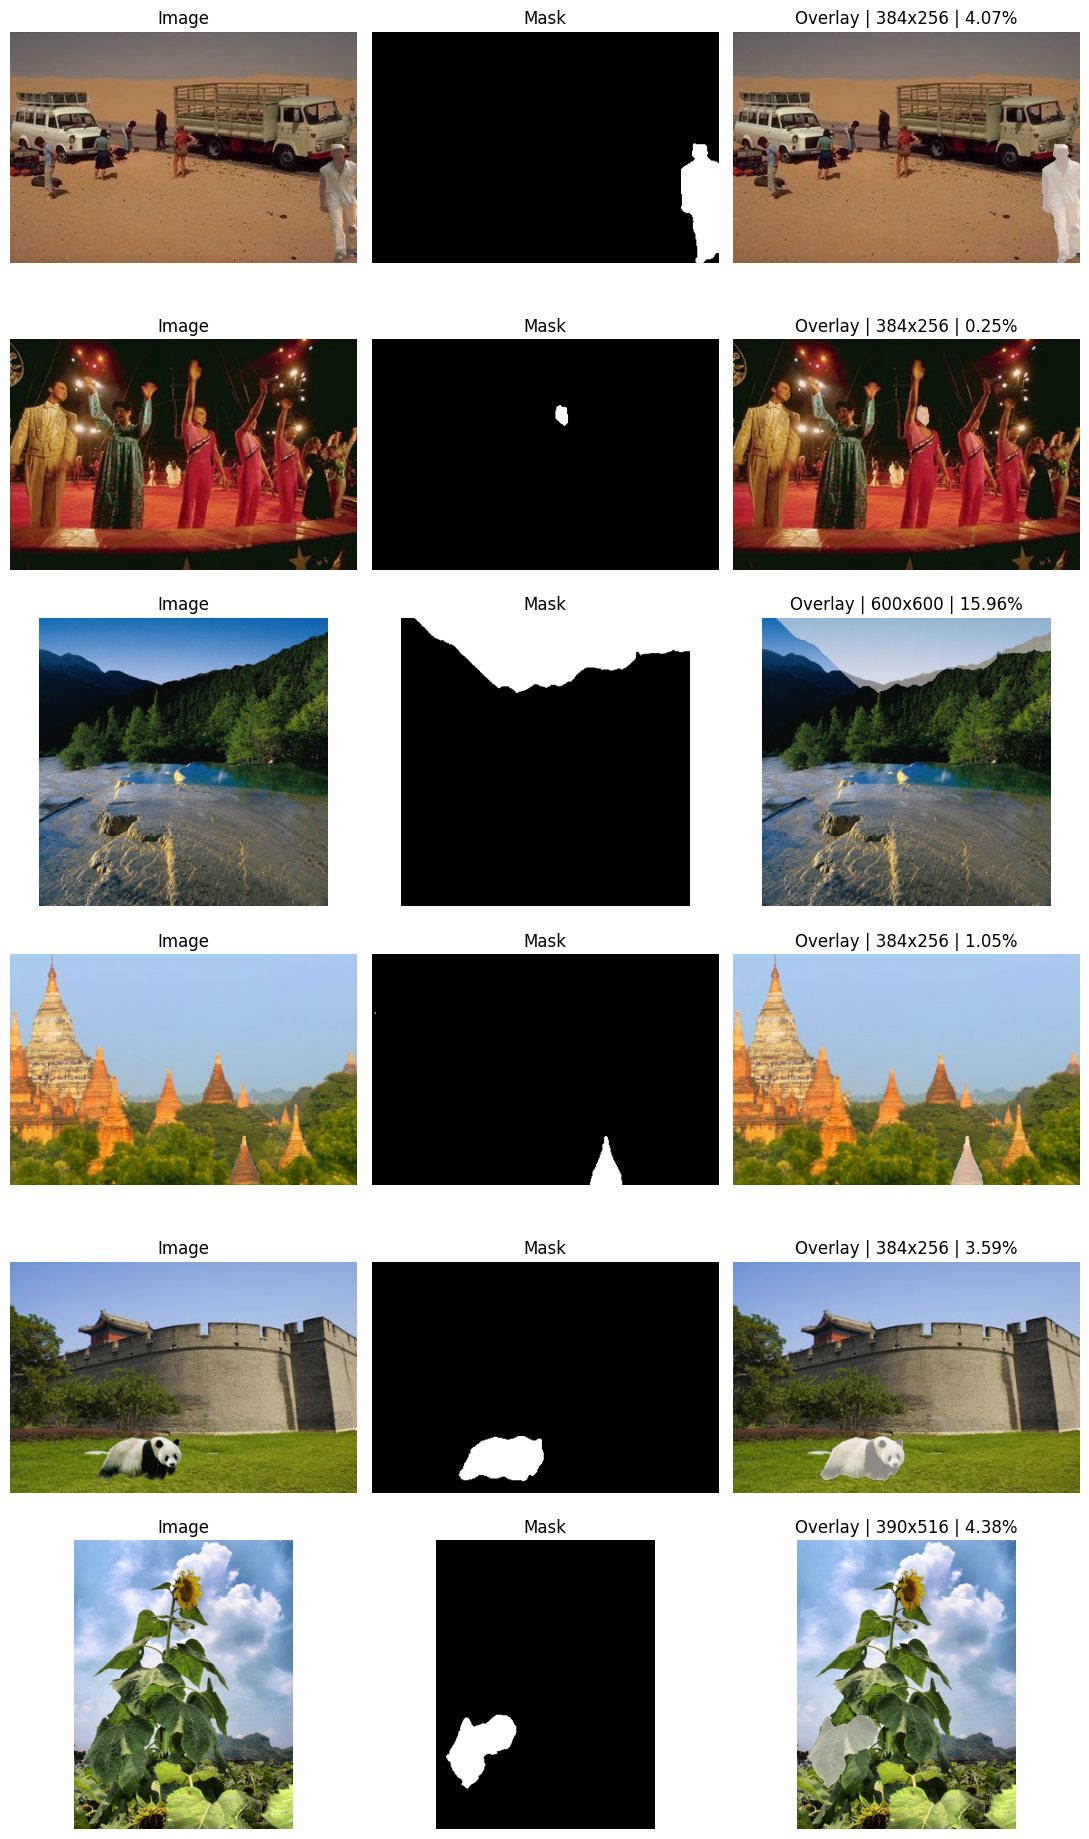

In [9]:
display(pd.crosstab(data.class_name, data.ext))
tif_rule = data.ext.isin([".tif", ".tiff"]).astype(int)
print("Shortcut rule 'TIFF => manipulated' on all rows:",
      "accuracy =", round(accuracy_score(data.label, tif_rule), 4),
      "| balanced accuracy =", round(balanced_accuracy_score(data.label, tif_rule), 4))
print("If this shortcut is far above 0.5, format normalisation (NORMALIZE_FORMAT) matters.\n")

def load_rgb(path):
    with Image.open(path) as im:
        return im.convert("RGB").copy()

def load_mask(path, size_wh):
    with Image.open(path) as im:
        m = im.convert("L")
    if m.size != tuple(size_wh):
        m = m.resize(tuple(size_wh), Image.Resampling.NEAREST)
    return np.asarray(m) > 0

aud = data[data.label == 1].sample(n=6, random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(len(aud), 3, figsize=(11, 3.1 * len(aud)))
for i, row in aud.iterrows():
    im = load_rgb(row.image_path); gt = load_mask(row.mask_path, im.size)
    axes[i, 0].imshow(im); axes[i, 0].set_title("Image")
    axes[i, 1].imshow(gt, cmap="gray"); axes[i, 1].set_title("Mask")
    axes[i, 2].imshow(im); axes[i, 2].imshow(np.ma.masked_where(~gt, gt), cmap="Reds", alpha=0.55)
    axes[i, 2].set_title(f"Overlay | {im.size[0]}x{im.size[1]} | {gt.mean()*100:.2f}%")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout(); plt.show()


## 5. Strict source-disjoint split (same logic and seeds as v3)

Rows sharing any normalised source ID are joined into one connected component, and every component lives in exactly one split. The largest component (~29 % of rows) must go to training. Training now uses **all** training rows; validation/test are capped at 250 per class exactly as in v3.


In [10]:
def add_strict_source_components(frame):
    tokens_by_row = [list(t) if isinstance(t, (list, tuple, set)) else [] for t in frame.source_tokens.tolist()]
    n = len(frame); parent = list(range(n)); rank = [0] * n
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb: return
        if rank[ra] < rank[rb]: ra, rb = rb, ra
        parent[rb] = ra
        if rank[ra] == rank[rb]: rank[ra] += 1
    owner = {}
    for i, tokens in enumerate(tokens_by_row):
        for token in tokens:
            if token in owner: union(i, owner[token])
            else: owner[token] = i
    roots = [find(i) for i in range(n)]
    root_to_group = {r: f"source_component_{j:06d}" for j, r in enumerate(sorted(set(roots)))}
    out = frame.copy(); out["group_id"] = [root_to_group[r] for r in roots]
    counts = out.groupby("group_id").size()
    return out, float(counts.max() / max(1, len(out))), len(counts)

data, LARGEST_COMPONENT_SHARE, COMPONENT_COUNT = add_strict_source_components(data)
print("Components:", COMPONENT_COUNT, "| largest share:", round(LARGEST_COMPONENT_SHARE, 4))

SPLIT_NAMES = ["train", "validation", "test"]
SPLIT_FRACS = {"train": 0.60, "validation": 0.20, "test": 0.20}
label_totals = {l: int((data.label == l).sum()) for l in (0, 1)}
component_stats = data.groupby("group_id").agg(
    n_rows=("label", "size"),
    authentic=("label", lambda x: int((x == 0).sum())),
    manipulated=("label", lambda x: int((x == 1).sum())),
).sort_values("n_rows", ascending=False)

largest_group = component_stats.index[0]
assigned = {s: [] for s in SPLIT_NAMES}
current = {s: {0: 0, 1: 0} for s in SPLIT_NAMES}
def group_label_counts(g):
    r = component_stats.loc[g]; return {0: int(r.authentic), 1: int(r.manipulated)}
def split_objective(proposed_split=None, proposed_counts=None):
    score = 0.0
    for s in SPLIT_NAMES:
        for l in (0, 1):
            obs = current[s][l]
            if proposed_split == s and proposed_counts is not None: obs += proposed_counts[l]
            score += ((obs - SPLIT_FRACS[s] * label_totals[l]) / max(1, label_totals[l])) ** 2
    return score

assigned["train"].append(largest_group)
for l, c in group_label_counts(largest_group).items(): current["train"][l] += c
remaining = list(component_stats.index[1:])
rng_groups = np.random.default_rng(SEED + 202)
tie = {g: float(rng_groups.random()) for g in remaining}
remaining.sort(key=lambda g: (-int(component_stats.loc[g, "n_rows"]), tie[g]))
for g in remaining:
    cnt = group_label_counts(g)
    obj = {s: split_objective(s, cnt) for s in SPLIT_NAMES}
    chosen = min(obj, key=obj.get)
    assigned[chosen].append(g)
    for l, c in cnt.items(): current[chosen][l] += c

split_map = {g: s for s, gs in assigned.items() for g in gs}
data["split_name"] = data.group_id.map(split_map)
train_all = data[data.split_name == "train"].copy().reset_index(drop=True)
val_all = data[data.split_name == "validation"].copy()
test_all = data[data.split_name == "test"].copy()

def cap_each_class(frame, cap, seed):
    parts = []
    for l in (0, 1):
        part = frame[frame.label == l]
        if len(part) > cap: part = part.sample(n=cap, random_state=seed + l)
        parts.append(part)
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

train_df = train_all
val_df = cap_each_class(val_all, MAX_VAL_PER_CLASS, SEED + 20)
test_df = cap_each_class(test_all, MAX_TEST_PER_CLASS, SEED + 30)

def token_union(f): return set(t for toks in f.source_tokens for t in toks)
tt, vt, et = token_union(train_all), token_union(val_all), token_union(test_all)
print("Shared source tokens train/val, train/test, val/test:", len(tt & vt), len(tt & et), len(vt & et))
if (tt & vt) or (tt & et) or (vt & et):
    raise RuntimeError("Source leakage detected; do not train.")

display(pd.DataFrame([{"split": n, "rows": len(f), "authentic": int((f.label == 0).sum()),
                       "manipulated": int((f.label == 1).sum())}
                      for n, f in [("train (all)", train_df), ("validation", val_df), ("test", test_df)]]))
for n, f in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    f.to_csv(OUTPUT_DIR / f"{n}_manifest.csv", index=False)

v3_manifest = Path("/kaggle/working/trace_x_outputs_v3/test_manifest.csv")
if v3_manifest.exists():
    old = pd.read_csv(v3_manifest)
    print("Test set identical to v3:", set(old.image_path) == set(test_df.image_path))
else:
    print("(v3 manifest not present in this session; test set should match v3 if the data order is unchanged.)")


Components: 6546 | largest share: 0.2932
Shared source tokens train/val, train/test, val/test: 0 0 0


,split,rows,authentic,manipulated
0,train (all),8061,4495,3566
1,validation,500,250,250
2,test,500,250,250


(v3 manifest not present in this session; test set should match v3 if the data order is unchanged.)


## 6. Input pipeline: native resolution, ELA channel, tamper-biased crops

- **No resizing.** Crops are cut at native resolution with 8-aligned offsets so JPEG block grids stay aligned; no flips (they would break grid alignment).
- **Format normalisation (optional):** every image is re-saved as JPEG at `NORMALIZE_QUALITY` before anything else, so file format alone cannot separate the classes. This also hides some real compression history, so treat it as an ablation switch.
- **ELA channel:** absolute difference to a JPEG re-save at `ELA_QUALITY`.
- **Crop sampling:** 80 % of manipulated-image crops are centred near the tampered region; authentic crops are random. The crop-level classification label is 1 only if the crop holds ≥ `MIN_POS_PIXELS` mask pixels.


In [11]:
def jpeg_roundtrip(img, quality):
    buf = io.BytesIO()
    img.convert("RGB").save(buf, format="JPEG", quality=int(quality))
    buf.seek(0)
    with Image.open(buf) as d:
        return d.convert("RGB").copy()

def make_ela(img):
    re_img = jpeg_roundtrip(img, ELA_QUALITY)
    diff = np.abs(np.asarray(img, dtype=np.int16) - np.asarray(re_img, dtype=np.int16)).mean(axis=2)
    return np.clip(diff * ELA_SCALE, 0, 255).astype(np.uint8)

def prepare_image(img):
    img = img.convert("RGB")
    if NORMALIZE_FORMAT:
        img = jpeg_roundtrip(img, NORMALIZE_QUALITY)
    return np.asarray(img, dtype=np.uint8), make_ela(img)

def to_tensor4(rgb, ela):
    return torch.from_numpy(np.concatenate([rgb.transpose(2, 0, 1).astype(np.float32) / 255.0,
                                            ela[None].astype(np.float32) / 255.0], axis=0))

def choose_origin(length, crop, center=None):
    if length <= crop: return 0
    if center is None:
        o = random.randint(0, length - crop)
    else:
        o = int(np.clip(center - crop // 2 + random.randint(-crop // 4, crop // 4), 0, length - crop))
    return (o // 8) * 8

class CASIACropDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = load_rgb(row.image_path)
        rgb, ela = prepare_image(img)
        h, w = ela.shape
        mask = load_mask(row.mask_path, (w, h)) if (row.label == 1 and row.mask_path) else np.zeros((h, w), bool)
        cy = cx = None
        if mask.any() and random.random() < POSITIVE_CROP_PROB:
            ys, xs = np.nonzero(mask); k = random.randrange(len(ys)); cy, cx = int(ys[k]), int(xs[k])
        C = CROP_SIZE
        y0, x0 = choose_origin(h, C, cy), choose_origin(w, C, cx)
        rgb_c, ela_c, m_c = rgb[y0:y0+C, x0:x0+C], ela[y0:y0+C, x0:x0+C], mask[y0:y0+C, x0:x0+C]
        ch, cw = ela_c.shape
        x = torch.zeros(4, C, C); y = torch.zeros(1, C, C); valid = torch.zeros(1, C, C)
        x[:, :ch, :cw] = to_tensor4(rgb_c, ela_c)
        y[0, :ch, :cw] = torch.from_numpy(m_c.astype(np.float32))
        valid[0, :ch, :cw] = 1.0
        label = torch.tensor(1.0 if m_c.sum() >= MIN_POS_PIXELS else 0.0)
        return x, y, valid, label

class CASIAFullDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        rgb, ela = prepare_image(load_rgb(row.image_path))
        h, w = ela.shape
        mask = load_mask(row.mask_path, (w, h)) if (row.label == 1 and row.mask_path) else np.zeros((h, w), bool)
        return to_tensor4(rgb, ela), torch.from_numpy(mask[None].astype(np.uint8)), torch.tensor(float(row.label)), row.image_path

class_counts = train_df.label.value_counts().to_dict()
sample_weights = train_df.label.map(lambda l: 1.0 / class_counts[l]).values
sampler = WeightedRandomSampler(torch.as_tensor(sample_weights, dtype=torch.double),
                                num_samples=SAMPLES_PER_EPOCH, replacement=True)
loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                 persistent_workers=(NUM_WORKERS > 0))
train_loader = DataLoader(CASIACropDataset(train_df), batch_size=BATCH_SIZE, sampler=sampler,
                          drop_last=True, **loader_kw)
val_loader = DataLoader(CASIAFullDataset(val_df), batch_size=1, shuffle=False, **loader_kw)
test_loader = DataLoader(CASIAFullDataset(test_df), batch_size=1, shuffle=False, **loader_kw)

xb, yb, vb, lb = next(iter(train_loader))
print("Train batch:", tuple(xb.shape), tuple(yb.shape), "| crops labelled manipulated:", int(lb.sum()), "/", len(lb))
print("Steps per epoch:", len(train_loader))


Train batch: (16, 4, 256, 256) (16, 1, 256, 256) | crops labelled manipulated: 5 / 16
Steps per epoch: 300


## 7. Model: 7-channel ResNet-18 U-Net with a high-resolution skip and an image-level head


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


TraceNet (7ch ResNet-18 U-Net, ImageNet-pretrained, ELA=True, SRM=True, normalize_format=True)
Parameters: 14,435,090


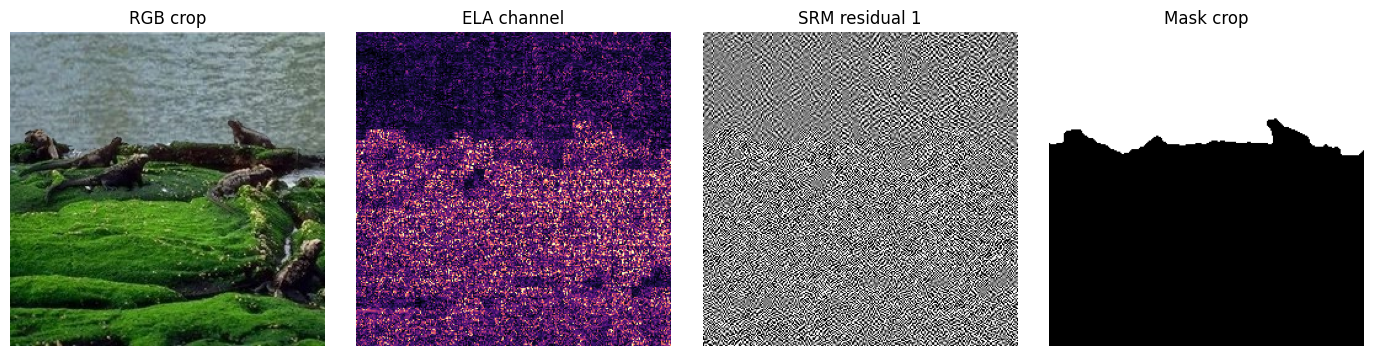

In [12]:
class ConvBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class SRMLayer(nn.Module):
    # Three fixed high-pass filters commonly used for noise-residual forensics, applied to luma.
    def __init__(self):
        super().__init__()
        k1 = np.array([[0,0,0,0,0],[0,-1,2,-1,0],[0,2,-4,2,0],[0,-1,2,-1,0],[0,0,0,0,0]], np.float32) / 4
        k2 = np.array([[-1,2,-2,2,-1],[2,-6,8,-6,2],[-2,8,-12,8,-2],[2,-6,8,-6,2],[-1,2,-2,2,-1]], np.float32) / 12
        k3 = np.array([[0,0,0,0,0],[0,0,0,0,0],[0,1,-2,1,0],[0,0,0,0,0],[0,0,0,0,0]], np.float32) / 2
        self.register_buffer("weight", torch.tensor(np.stack([k1, k2, k3]))[:, None])
    def forward(self, rgb):
        gray = (0.299 * rgb[:, 0:1] + 0.587 * rgb[:, 1:2] + 0.114 * rgb[:, 2:3]) * 255.0
        return torch.clamp(F.conv2d(gray, self.weight, padding=2), -3, 3) / 3

class TraceNet(nn.Module):
    def __init__(self, tv_models, pretrained=True):
        super().__init__()
        self.loaded_pretrained = False
        try:
            weights = tv_models.ResNet18_Weights.DEFAULT if pretrained else None
            bb = tv_models.resnet18(weights=weights); self.loaded_pretrained = weights is not None
        except Exception as exc:
            print("Pretrained weights unavailable; random init.", repr(exc))
            bb = tv_models.resnet18(weights=None)
        old = bb.conv1.weight.data
        conv1 = nn.Conv2d(7, 64, 7, 2, 3, bias=False)
        with torch.no_grad():
            conv1.weight[:, :3] = old
            conv1.weight[:, 3:] = old.mean(1, keepdim=True).repeat(1, 4, 1, 1) * 0.5
        self.conv1, self.bn1, self.relu, self.maxpool = conv1, bb.bn1, bb.relu, bb.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = bb.layer1, bb.layer2, bb.layer3, bb.layer4
        self.srm = SRMLayer()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.hires = ConvBlock(7, 16)
        self.dec4, self.dec3 = ConvBlock(512 + 256, 256), ConvBlock(256 + 128, 128)
        self.dec2, self.dec1 = ConvBlock(128 + 64, 64), ConvBlock(64 + 64, 64)
        self.final = nn.Sequential(ConvBlock(64 + 16, 32), nn.Conv2d(32, 1, 1))
        self.cls = nn.Sequential(nn.Dropout(0.3), nn.Linear(1024, 1))

    def build_input(self, x):
        rgb, ela = x[:, :3], x[:, 3:4]
        srm = self.srm(rgb)
        if not USE_SRM: srm = srm * 0
        ela = (ela - 0.15) / 0.25
        if not USE_ELA: ela = ela * 0
        return torch.cat([(rgb - self.mean) / self.std, ela, srm], dim=1)

    @staticmethod
    def up_cat(x, skip, block):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return block(torch.cat([x, skip], dim=1))

    def forward(self, x):
        inp = self.build_input(x)
        c0 = self.relu(self.bn1(self.conv1(inp)))
        c1 = self.layer1(self.maxpool(c0)); c2 = self.layer2(c1); c3 = self.layer3(c2); c4 = self.layer4(c3)
        d = self.up_cat(c4, c3, self.dec4); d = self.up_cat(d, c2, self.dec3)
        d = self.up_cat(d, c1, self.dec2); d = self.up_cat(d, c0, self.dec1)
        d = F.interpolate(d, size=inp.shape[-2:], mode="bilinear", align_corners=False)
        seg = self.final(torch.cat([d, self.hires(inp)], dim=1))
        pooled = torch.cat([c4.mean(dim=(2, 3)), c4.amax(dim=(2, 3))], dim=1)
        return seg, self.cls(pooled)[:, 0]

import torchvision.models as tv_models
model = TraceNet(tv_models, USE_PRETRAINED_ENCODER).to(DEVICE)
MODEL_DESCRIPTION = ("TraceNet (7ch ResNet-18 U-Net, " +
                     ("ImageNet-pretrained" if model.loaded_pretrained else "random-init") +
                     f", ELA={USE_ELA}, SRM={USE_SRM}, normalize_format={NORMALIZE_FORMAT})")
print(MODEL_DESCRIPTION)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

# Sanity view of the forensic channels on one tampered crop
xs, ys_, _, _ = CASIACropDataset(train_df[train_df.label == 1].head(1))[0]
with torch.no_grad():
    srm_vis = model.srm(xs[None].to(DEVICE))[0].cpu().numpy()
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
ax[0].imshow(xs[:3].permute(1, 2, 0).numpy()); ax[0].set_title("RGB crop")
ax[1].imshow(xs[3].numpy(), cmap="magma"); ax[1].set_title("ELA channel")
ax[2].imshow(srm_vis[0], cmap="gray"); ax[2].set_title("SRM residual 1")
ax[3].imshow(ys_[0].numpy(), cmap="gray"); ax[3].set_title("Mask crop")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()


## 8. Training

Loss = weighted BCE + 0.5 · batch Dice (segmentation) + 0.5 · BCE (crop-level classification). The best checkpoint is chosen by `0.5·AUC + 0.5·Dice` on the validation set (full-resolution images), **not** by loss. Training stops after `PATIENCE` epochs without improvement or when `TIME_BUDGET_MIN` is exhausted. Test data is never touched here.


  epoch 1 batch 100/300 | loss=1.6225
  epoch 1 batch 200/300 | loss=1.5576
  epoch 1 batch 300/300 | loss=1.5118


val:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1/24 | loss=1.5118 | val AUC=0.682 | val Dice=0.122 | score=0.402 | 62s
  -> new best checkpoint
  epoch 2 batch 100/300 | loss=1.3396
  epoch 2 batch 200/300 | loss=1.3124
  epoch 2 batch 300/300 | loss=1.2801


val:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 2/24 | loss=1.2801 | val AUC=0.734 | val Dice=0.157 | score=0.445 | 58s
  -> new best checkpoint
  epoch 3 batch 100/300 | loss=1.1706
  epoch 3 batch 200/300 | loss=1.1302
  epoch 3 batch 300/300 | loss=1.0884


val:   0%|          | 0/500 [00:00<?, ?it/s]

... (38 outputs left out)

Epoch 22/24 | loss=0.2093 | val AUC=0.935 | val Dice=0.396 | score=0.666 | 59s
  epoch 23 batch 100/300 | loss=0.1851
  epoch 23 batch 200/300 | loss=0.1757
  epoch 23 batch 300/300 | loss=0.1804


val:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 23/24 | loss=0.1804 | val AUC=0.936 | val Dice=0.399 | score=0.667 | 59s
Early stopping.
Loaded best checkpoint from epoch 17


,epoch,train_loss,train_seg,train_cls,val_cls_auc,val_best_dice,selection_score,seconds
0,1,1.5118,1.1113,0.8011,0.6818,0.1221,0.4020,61.8224
1,2,1.2801,0.9592,0.6419,0.7337,0.1565,0.4451,58.1972
2,3,1.0884,0.8019,0.5729,0.7590,0.2280,0.4935,59.6748
3,4,0.8345,0.6205,0.4280,0.9024,0.2595,0.5810,59.3061
4,5,0.7098,0.5316,0.3563,0.9106,0.3055,0.6080,59.5658
5,6,0.6541,0.4880,0.3323,0.9204,0.3415,0.6310,59.3398
6,7,0.6088,0.4532,0.3112,0.9127,0.3117,0.6122,59.2040
7,8,0.5245,0.3896,0.2698,0.9346,0.3432,0.6389,59.1584
8,9,0.5273,0.4012,0.2522,0.9393,0.3574,0.6484,59.2898
9,10,0.4672,0.3493,0.2357,0.9199,0.3431,0.6315,59.2816


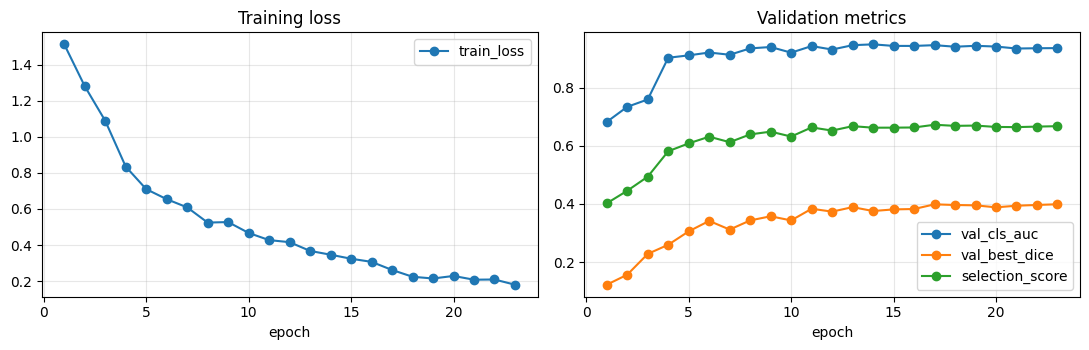

In [13]:
def compute_loss(seg_logits, cls_logits, masks, valid, labels):
    pw = torch.tensor([POS_WEIGHT], device=seg_logits.device)
    bce_map = F.binary_cross_entropy_with_logits(seg_logits, masks, pos_weight=pw, reduction="none")
    bce = (bce_map * valid).sum() / valid.sum().clamp_min(1.0)
    p = torch.sigmoid(seg_logits) * valid; t = masks * valid
    dice = (2 * (p * t).sum() + 1.0) / (p.sum() + t.sum() + 1.0)
    seg = bce + DICE_WEIGHT * (1.0 - dice)
    cls = F.binary_cross_entropy_with_logits(cls_logits, labels)
    return seg + CLS_WEIGHT * cls, seg.detach(), cls.detach()

@torch.no_grad()
def forward_full(x):
    # x: (1, 4, H, W) on DEVICE. Pads to a multiple of 32, runs the full-resolution image, crops back.
    _, _, H, W = x.shape
    xp = F.pad(x, (0, (32 - W % 32) % 32, 0, (32 - H % 32) % 32))
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        seg, cl = model(xp)
    prob = torch.sigmoid(seg.float())[0, 0, :H, :W].cpu().numpy().astype(np.float16)
    return prob, float(torch.sigmoid(cl.float())[0])

@torch.no_grad()
def infer_loader(loader, desc):
    model.eval()
    res = {"prob": [], "mask": [], "label": [], "path": [], "cls": []}
    for x, m, lab, path in tqdm(loader, desc=desc, leave=False):
        prob, c = forward_full(x.to(DEVICE, non_blocking=True))
        res["prob"].append(prob); res["mask"].append(m[0, 0].numpy().astype(bool))
        res["label"].append(int(lab[0])); res["path"].append(path[0]); res["cls"].append(c)
    res["label"] = np.asarray(res["label"]); res["cls"] = np.asarray(res["cls"])
    return res

def selection_metrics(res):
    labels = res["label"]
    auc = roc_auc_score(labels, res["cls"])
    pos = [i for i in range(len(labels)) if labels[i] == 1]
    best = 0.0
    for t in (0.3, 0.5, 0.7):
        ds = []
        for i in pos:
            p = res["prob"][i].astype(np.float32) >= t; m = res["mask"][i]
            ds.append(2.0 * (p & m).sum() / max(1, p.sum() + m.sum()))
        best = max(best, float(np.mean(ds)))
    return auc, best, 0.5 * auc + 0.5 * best

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LEARNING_RATE,
                                                total_steps=EPOCHS * steps_per_epoch, pct_start=0.15)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
CKPT_LAST, CKPT_BEST = OUTPUT_DIR / "checkpoint_last.pt", OUTPUT_DIR / "model_best.pt"
history, start_epoch, best_score, bad_epochs = [], 0, -1.0, 0

if RESUME_TRAINING and CKPT_LAST.exists():
    ck = torch.load(CKPT_LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model_state_dict"]); optimizer.load_state_dict(ck["optimizer_state_dict"])
    scheduler.load_state_dict(ck["scheduler_state_dict"])
    start_epoch, best_score, history = ck["epoch"], ck["best_score"], ck["history"]
    print("Resumed after epoch", start_epoch)

t_start = time.time()
for epoch in range(start_epoch, EPOCHS):
    t0 = time.time(); model.train()
    losses, seg_l, cls_l = [], [], []
    for b, (x, y, valid, lab) in enumerate(train_loader, start=1):
        x, y, valid, lab = [t.to(DEVICE, non_blocking=True) for t in (x, y, valid, lab)]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            seg, cl = model(x)
        loss, sl, cl_loss = compute_loss(seg.float(), cl.float(), y, valid, lab)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        losses.append(float(loss)); seg_l.append(float(sl)); cls_l.append(float(cl_loss))
        if b % 100 == 0:
            print(f"  epoch {epoch+1} batch {b}/{steps_per_epoch} | loss={np.mean(losses):.4f}")
    val_res = infer_loader(val_loader, "val")
    auc, dice, score = selection_metrics(val_res)
    row = {"epoch": epoch + 1, "train_loss": np.mean(losses), "train_seg": np.mean(seg_l), "train_cls": np.mean(cls_l),
           "val_cls_auc": auc, "val_best_dice": dice, "selection_score": score, "seconds": time.time() - t0}
    history.append(row)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss={row['train_loss']:.4f} | val AUC={auc:.3f} | val Dice={dice:.3f} | "
          f"score={score:.3f} | {row['seconds']:.0f}s")
    state = {"epoch": epoch + 1, "model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
             "scheduler_state_dict": scheduler.state_dict(), "best_score": max(best_score, score), "history": history,
             "model_description": MODEL_DESCRIPTION}
    torch.save(state, CKPT_LAST)
    if score > best_score:
        best_score, bad_epochs = score, 0
        torch.save(state, CKPT_BEST); print("  -> new best checkpoint")
    else:
        bad_epochs += 1
    if bad_epochs >= PATIENCE:
        print("Early stopping."); break
    if (time.time() - t_start) / 60 > TIME_BUDGET_MIN:
        print("Time budget reached."); break

history_df = pd.DataFrame(history); history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
best = torch.load(CKPT_BEST, map_location=DEVICE, weights_only=False)
model.load_state_dict(best["model_state_dict"])
print("Loaded best checkpoint from epoch", best["epoch"])
display(history_df.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
history_df.set_index("epoch")[["train_loss"]].plot(ax=ax[0], marker="o"); ax[0].set_title("Training loss"); ax[0].grid(alpha=.3)
history_df.set_index("epoch")[["val_cls_auc", "val_best_dice", "selection_score"]].plot(ax=ax[1], marker="o")
ax[1].set_title("Validation metrics"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


## 9. Calibrate thresholds on validation data only

1. **Image score source:** classification head (`cls`) vs the 99.5th percentile of the probability map (`seg`), picked by validation AUC.
2. **Image threshold:** two operating points chosen on validation: best balanced accuracy, and best recall with validation FPR ≤ 10 %.
3. **Pixel threshold:** best validation IoU on manipulated images subject to ≤ 5 % mean predicted area on authentic images (fallback: lowest authentic area).


In [14]:
val_res = infer_loader(val_loader, "validation")
test_res = infer_loader(test_loader, "test")

def seg_score(prob): return float(np.quantile(prob.astype(np.float32), 0.995))
val_seg = np.array([seg_score(p) for p in val_res["prob"]])
test_seg = np.array([seg_score(p) for p in test_res["prob"]])
auc_cls, auc_seg = roc_auc_score(val_res["label"], val_res["cls"]), roc_auc_score(val_res["label"], val_seg)
IMAGE_SCORE_SOURCE = "cls" if auc_cls >= auc_seg else "seg"
print(f"Validation AUC  cls head: {auc_cls:.4f} | seg max-score: {auc_seg:.4f}  -> using '{IMAGE_SCORE_SOURCE}'")
val_scores = val_res["cls"] if IMAGE_SCORE_SOURCE == "cls" else val_seg
test_scores = test_res["cls"] if IMAGE_SCORE_SOURCE == "cls" else test_seg

def choose_threshold(scores, labels, max_fpr=None):
    best_t, best_key = None, None
    for t in np.unique(np.quantile(scores, np.linspace(0, 1, 401))):
        pred = scores >= t
        fpr = float(np.mean(pred[labels == 0]))
        if max_fpr is not None and fpr > max_fpr: continue
        tpr = float(np.mean(pred[labels == 1]))
        key = (tpr,) if max_fpr is not None else (0.5 * (tpr + 1 - fpr), -fpr)
        if best_key is None or key > best_key: best_t, best_key = float(t), key
    return best_t if best_t is not None else float(np.max(scores) + 1e-6)

THRESH_BALANCED = choose_threshold(val_scores, val_res["label"])
THRESH_LOWFPR = choose_threshold(val_scores, val_res["label"], max_fpr=0.10)
IMAGE_SCORE_THRESHOLD = THRESH_BALANCED
print("Image thresholds -> balanced:", round(THRESH_BALANCED, 4), "| FPR<=10%:", round(THRESH_LOWFPR, 4))

PIXEL_GRID = np.round(np.arange(0.10, 0.91, 0.05), 3)
def sweep(res, thresholds):
    n, T = len(res["prob"]), len(thresholds)
    tp, fp, fn = (np.zeros((n, T), dtype=np.int64) for _ in range(3)); size = np.zeros(n)
    for i in range(n):
        p32 = res["prob"][i].astype(np.float32); m = res["mask"][i]; size[i] = m.size
        for j, t in enumerate(thresholds):
            pr = p32 >= t
            tp[i, j] = (pr & m).sum(); fp[i, j] = (pr & ~m).sum(); fn[i, j] = (~pr & m).sum()
    return tp, fp, fn, size

def iou_dice(tp, fp, fn):
    u = tp + fp + fn; d = 2 * tp + fp + fn
    return np.where(u > 0, tp / np.maximum(u, 1), np.nan), np.where(d > 0, 2 * tp / np.maximum(d, 1), np.nan)

tp, fp, fn, size = sweep(val_res, PIXEL_GRID)
pos, neg = val_res["label"] == 1, val_res["label"] == 0
v_iou, v_dice = iou_dice(tp[pos], fp[pos], fn[pos])
rows = pd.DataFrame({"pixel_threshold": PIXEL_GRID,
                     "val_mean_IoU": np.nanmean(v_iou, axis=0), "val_mean_Dice": np.nanmean(v_dice, axis=0),
                     "val_authentic_area": ((tp[neg] + fp[neg]) / size[neg][:, None]).mean(axis=0)})
ok = rows[rows.val_authentic_area <= MAX_AUTHENTIC_PREDICTED_AREA]
if len(ok):
    sel = ok.sort_values(["val_mean_IoU", "pixel_threshold"], ascending=[False, False]).iloc[0]
    print(f"Pixel threshold: best val IoU with authentic area <= {MAX_AUTHENTIC_PREDICTED_AREA:.0%}")
else:
    sel = rows.sort_values(["val_authentic_area", "val_mean_IoU"], ascending=[True, False]).iloc[0]
    print("WARNING: no threshold met the authentic-area budget; using the lowest authentic area.")
PIXEL_THRESHOLD = float(sel.pixel_threshold)
print("Selected pixel threshold:", PIXEL_THRESHOLD, "| val IoU:", round(float(sel.val_mean_IoU), 4),
      "| val authentic area:", round(float(sel.val_authentic_area), 4))
display(rows.round(4))
rows.to_csv(OUTPUT_DIR / "validation_pixel_threshold_sweep.csv", index=False)


validation:   0%|          | 0/500 [00:00<?, ?it/s]

test:   0%|          | 0/500 [00:00<?, ?it/s]

Validation AUC  cls head: 0.9457 | seg max-score: 0.9373  -> using 'cls'
Image thresholds -> balanced: 0.0604 | FPR<=10%: 0.3528
Pixel threshold: best val IoU with authentic area <= 5%
Selected pixel threshold: 0.35 | val IoU: 0.3552 | val authentic area: 0.01


,pixel_threshold,val_mean_IoU,val_mean_Dice,val_authentic_area
0,0.10,0.3481,0.4004,0.0186
1,0.15,0.3500,0.3992,0.0146
2,0.20,0.3530,0.3997,0.0126
3,0.25,0.3545,0.3992,0.0115
4,0.30,0.3549,0.3985,0.0107
5,0.35,0.3552,0.3979,0.0100
6,0.40,0.3551,0.3970,0.0095
7,0.45,0.3548,0.3958,0.0090
8,0.50,0.3544,0.3948,0.0086
9,0.55,0.3540,0.3939,0.0083


## 10. Final test evaluation (untouched test set)


In [15]:
labels = test_res["label"]
def image_report(thr, name):
    pred = (test_scores >= thr).astype(int)
    return {"operating_point": name, "threshold": round(thr, 4),
            "accuracy": accuracy_score(labels, pred), "balanced_acc": balanced_accuracy_score(labels, pred),
            "precision": precision_score(labels, pred, zero_division=0), "recall": recall_score(labels, pred, zero_division=0),
            "f1": f1_score(labels, pred, zero_division=0), "FPR_authentic": float(np.mean(pred[labels == 0]))}
img_table = pd.DataFrame([image_report(THRESH_BALANCED, "balanced accuracy"), image_report(THRESH_LOWFPR, "val FPR<=10%")])
TEST_AUC = float(roc_auc_score(labels, test_scores))
print(f"IMAGE-LEVEL DETECTION (score source: {IMAGE_SCORE_SOURCE}) | test ROC-AUC = {TEST_AUC:.4f}")
print("  (cls AUC:", round(roc_auc_score(labels, test_res['cls']), 4), "| seg AUC:", round(roc_auc_score(labels, test_seg), 4), ")")
display(img_table.round(4))
print("Confusion matrix [[TN, FP], [FN, TP]] at balanced threshold:")
print(confusion_matrix(labels, (test_scores >= THRESH_BALANCED).astype(int), labels=[0, 1]))

tp, fp, fn, size = sweep(test_res, [PIXEL_THRESHOLD])
tp, fp, fn = tp[:, 0], fp[:, 0], fn[:, 0]
pos, neg = labels == 1, labels == 0
iou_u, dice_u = iou_dice(tp, fp, fn)
gate = test_scores >= THRESH_BALANCED
tp_g, fp_g = np.where(gate, tp, 0), np.where(gate, fp, 0)
fn_g = np.where(gate, fn, tp + fn)
iou_g, dice_g = iou_dice(tp_g, fp_g, fn_g)

def loc_summary(iou, dice, tp_, fp_, fn_):
    prec = np.where(tp_ + fp_ > 0, tp_ / np.maximum(tp_ + fp_, 1), 0.0)
    rec = np.where(tp_ + fn_ > 0, tp_ / np.maximum(tp_ + fn_, 1), 0.0)
    return {"mean_IoU": np.nanmean(iou[pos]), "median_IoU": np.nanmedian(iou[pos]), "mean_Dice": np.nanmean(dice[pos]),
            "median_Dice": np.nanmedian(dice[pos]), "mean_precision": prec[pos].mean(), "mean_recall": rec[pos].mean(),
            "frac_images_IoU>0.1": float(np.mean(iou[pos] > 0.1)), "frac_images_IoU=0": float(np.mean(iou[pos] == 0))}
loc_table = pd.DataFrame({"ungated (always output mask)": loc_summary(iou_u, dice_u, tp, fp, fn),
                          "gated by image decision": loc_summary(iou_g, dice_g, tp_g, fp_g, fn_g)}).T
print(f"\nPIXEL LOCALIZATION on manipulated test images (pixel threshold {PIXEL_THRESHOLD})")
display(loc_table.round(4))
auth_area = (tp + fp)[neg] / size[neg]
print("Authentic images: mean predicted area =", round(float(auth_area.mean()), 4),
      "| fraction with >1% flagged =", round(float(np.mean(auth_area > 0.01)), 3))

test_pred_df = pd.DataFrame({"image_path": test_res["path"], "true_label": labels, "cls_prob": test_res["cls"],
                             "seg_score": test_seg, "image_score": test_scores,
                             "pred_balanced": (test_scores >= THRESH_BALANCED).astype(int),
                             "gt_area_fraction": [m.mean() for m in test_res["mask"]],
                             "pred_area_fraction": (tp + fp) / size, "IoU_ungated": iou_u, "Dice_ungated": dice_u})
test_pred_df["ext"] = test_pred_df.image_path.map(lambda p: Path(p).suffix.lower())
test_pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
img_table.to_csv(OUTPUT_DIR / "test_image_metrics.csv", index=False)
loc_table.to_csv(OUTPUT_DIR / "test_localization_metrics.csv")


IMAGE-LEVEL DETECTION (score source: cls) | test ROC-AUC = 0.9456
  (cls AUC: 0.9456 | seg AUC: 0.9218 )


,operating_point,threshold,accuracy,balanced_acc,precision,recall,f1,FPR_authentic
0,balanced accuracy,0.0604,0.890,0.890,0.8545,0.940,0.8952,0.16
1,val FPR<=10%,0.3528,0.862,0.862,0.8918,0.824,0.8565,0.10


Confusion matrix [[TN, FP], [FN, TP]] at balanced threshold:
[[210  40]
 [ 15 235]]

PIXEL LOCALIZATION on manipulated test images (pixel threshold 0.35)


,mean_IoU,median_IoU,mean_Dice,median_Dice,mean_precision,mean_recall,frac_images_IoU>0.1,frac_images_IoU=0
ungated (always output mask),0.3788,0.1121,0.4238,0.2014,0.4326,0.4925,0.5,0.38
gated by image decision,0.3788,0.1121,0.4238,0.2014,0.4326,0.4925,0.5,0.38


Authentic images: mean predicted area = 0.0076 | fraction with >1% flagged = 0.088


## 11. Where does it work? Breakdown by file format and tampered-region size

A large gap between TIFF and JPEG rows indicates the model is still keyed to format or compression history rather than manipulation.


In [16]:
b = test_pred_df.copy(); b["pred"] = b.pred_balanced
fmt = []
for ext, g in b.groupby("ext"):
    row = {"ext": ext, "n_authentic": int((g.true_label == 0).sum()), "n_manipulated": int((g.true_label == 1).sum())}
    if (g.true_label == 0).any(): row["FPR_authentic"] = float(g.loc[g.true_label == 0, "pred"].mean())
    if (g.true_label == 1).any():
        row["recall_manipulated"] = float(g.loc[g.true_label == 1, "pred"].mean())
        row["mean_IoU_manipulated"] = float(g.loc[g.true_label == 1, "IoU_ungated"].mean())
    fmt.append(row)
print("By file extension:"); display(pd.DataFrame(fmt).round(3))

m = b[b.true_label == 1].copy()
m["area_bin"] = pd.cut(m.gt_area_fraction, [0, 0.01, 0.03, 0.10, 1.0], labels=["<1%", "1-3%", "3-10%", ">10%"])
print("By tampered-region size:")
display(m.groupby("area_bin", observed=True).agg(n=("pred", "size"), detection_recall=("pred", "mean"),
                                                 mean_IoU=("IoU_ungated", "mean"), mean_Dice=("Dice_ungated", "mean")).round(3))


By file extension:


,ext,n_authentic,n_manipulated,FPR_authentic,recall_manipulated,mean_IoU_manipulated
0,.bmp,2,0,0.500,NaN,NaN
1,.jpg,248,78,0.157,0.962,0.306
2,.tif,0,172,NaN,0.930,0.412


By tampered-region size:


,n,detection_recall,mean_IoU,mean_Dice
area_bin,,,,
<1%,79,0.886,0.246,0.290
1-3%,59,0.983,0.332,0.382
3-10%,66,0.955,0.473,0.525
>10%,46,0.957,0.533,0.563


## 12. Comparison with the v3 run


In [17]:
# v3 reference values copied from the v3 run on this same split (strict source-disjoint, 250/250 test).
v3 = {"accuracy": 0.620, "ROC-AUC": 0.687, "recall (manipulated)": 0.536, "FPR (authentic)": 0.296,
      "mean IoU": 0.0636, "median IoU": 0.0, "mean Dice": 0.0958}
bal = img_table.iloc[0]
v4 = {"accuracy": bal.accuracy, "ROC-AUC": TEST_AUC, "recall (manipulated)": bal.recall, "FPR (authentic)": bal.FPR_authentic,
      "mean IoU": loc_table.loc["ungated (always output mask)", "mean_IoU"],
      "median IoU": loc_table.loc["ungated (always output mask)", "median_IoU"],
      "mean Dice": loc_table.loc["ungated (always output mask)", "mean_Dice"]}
cmp_df = pd.DataFrame({"v3": v3, "v4": v4}); cmp_df["change"] = cmp_df.v4 - cmp_df.v3
display(cmp_df.round(4)); cmp_df.to_csv(OUTPUT_DIR / "v3_vs_v4.csv")
print("Read this honestly: improvements of a few points on 250 images per class are within sampling noise; "
      "differences should be large and consistent across metrics before you claim progress.")


,v3,v4,change
accuracy,0.6200,0.8900,0.2700
ROC-AUC,0.6870,0.9456,0.2586
recall (manipulated),0.5360,0.9400,0.4040
FPR (authentic),0.2960,0.1600,-0.1360
mean IoU,0.0636,0.3788,0.3152
median IoU,0.0000,0.1121,0.1121
mean Dice,0.0958,0.4238,0.3280


Read this honestly: improvements of a few points on 250 images per class are within sampling noise; differences should be large and consistent across metrics before you claim progress.


## 13. Visual check on held-out manipulated images


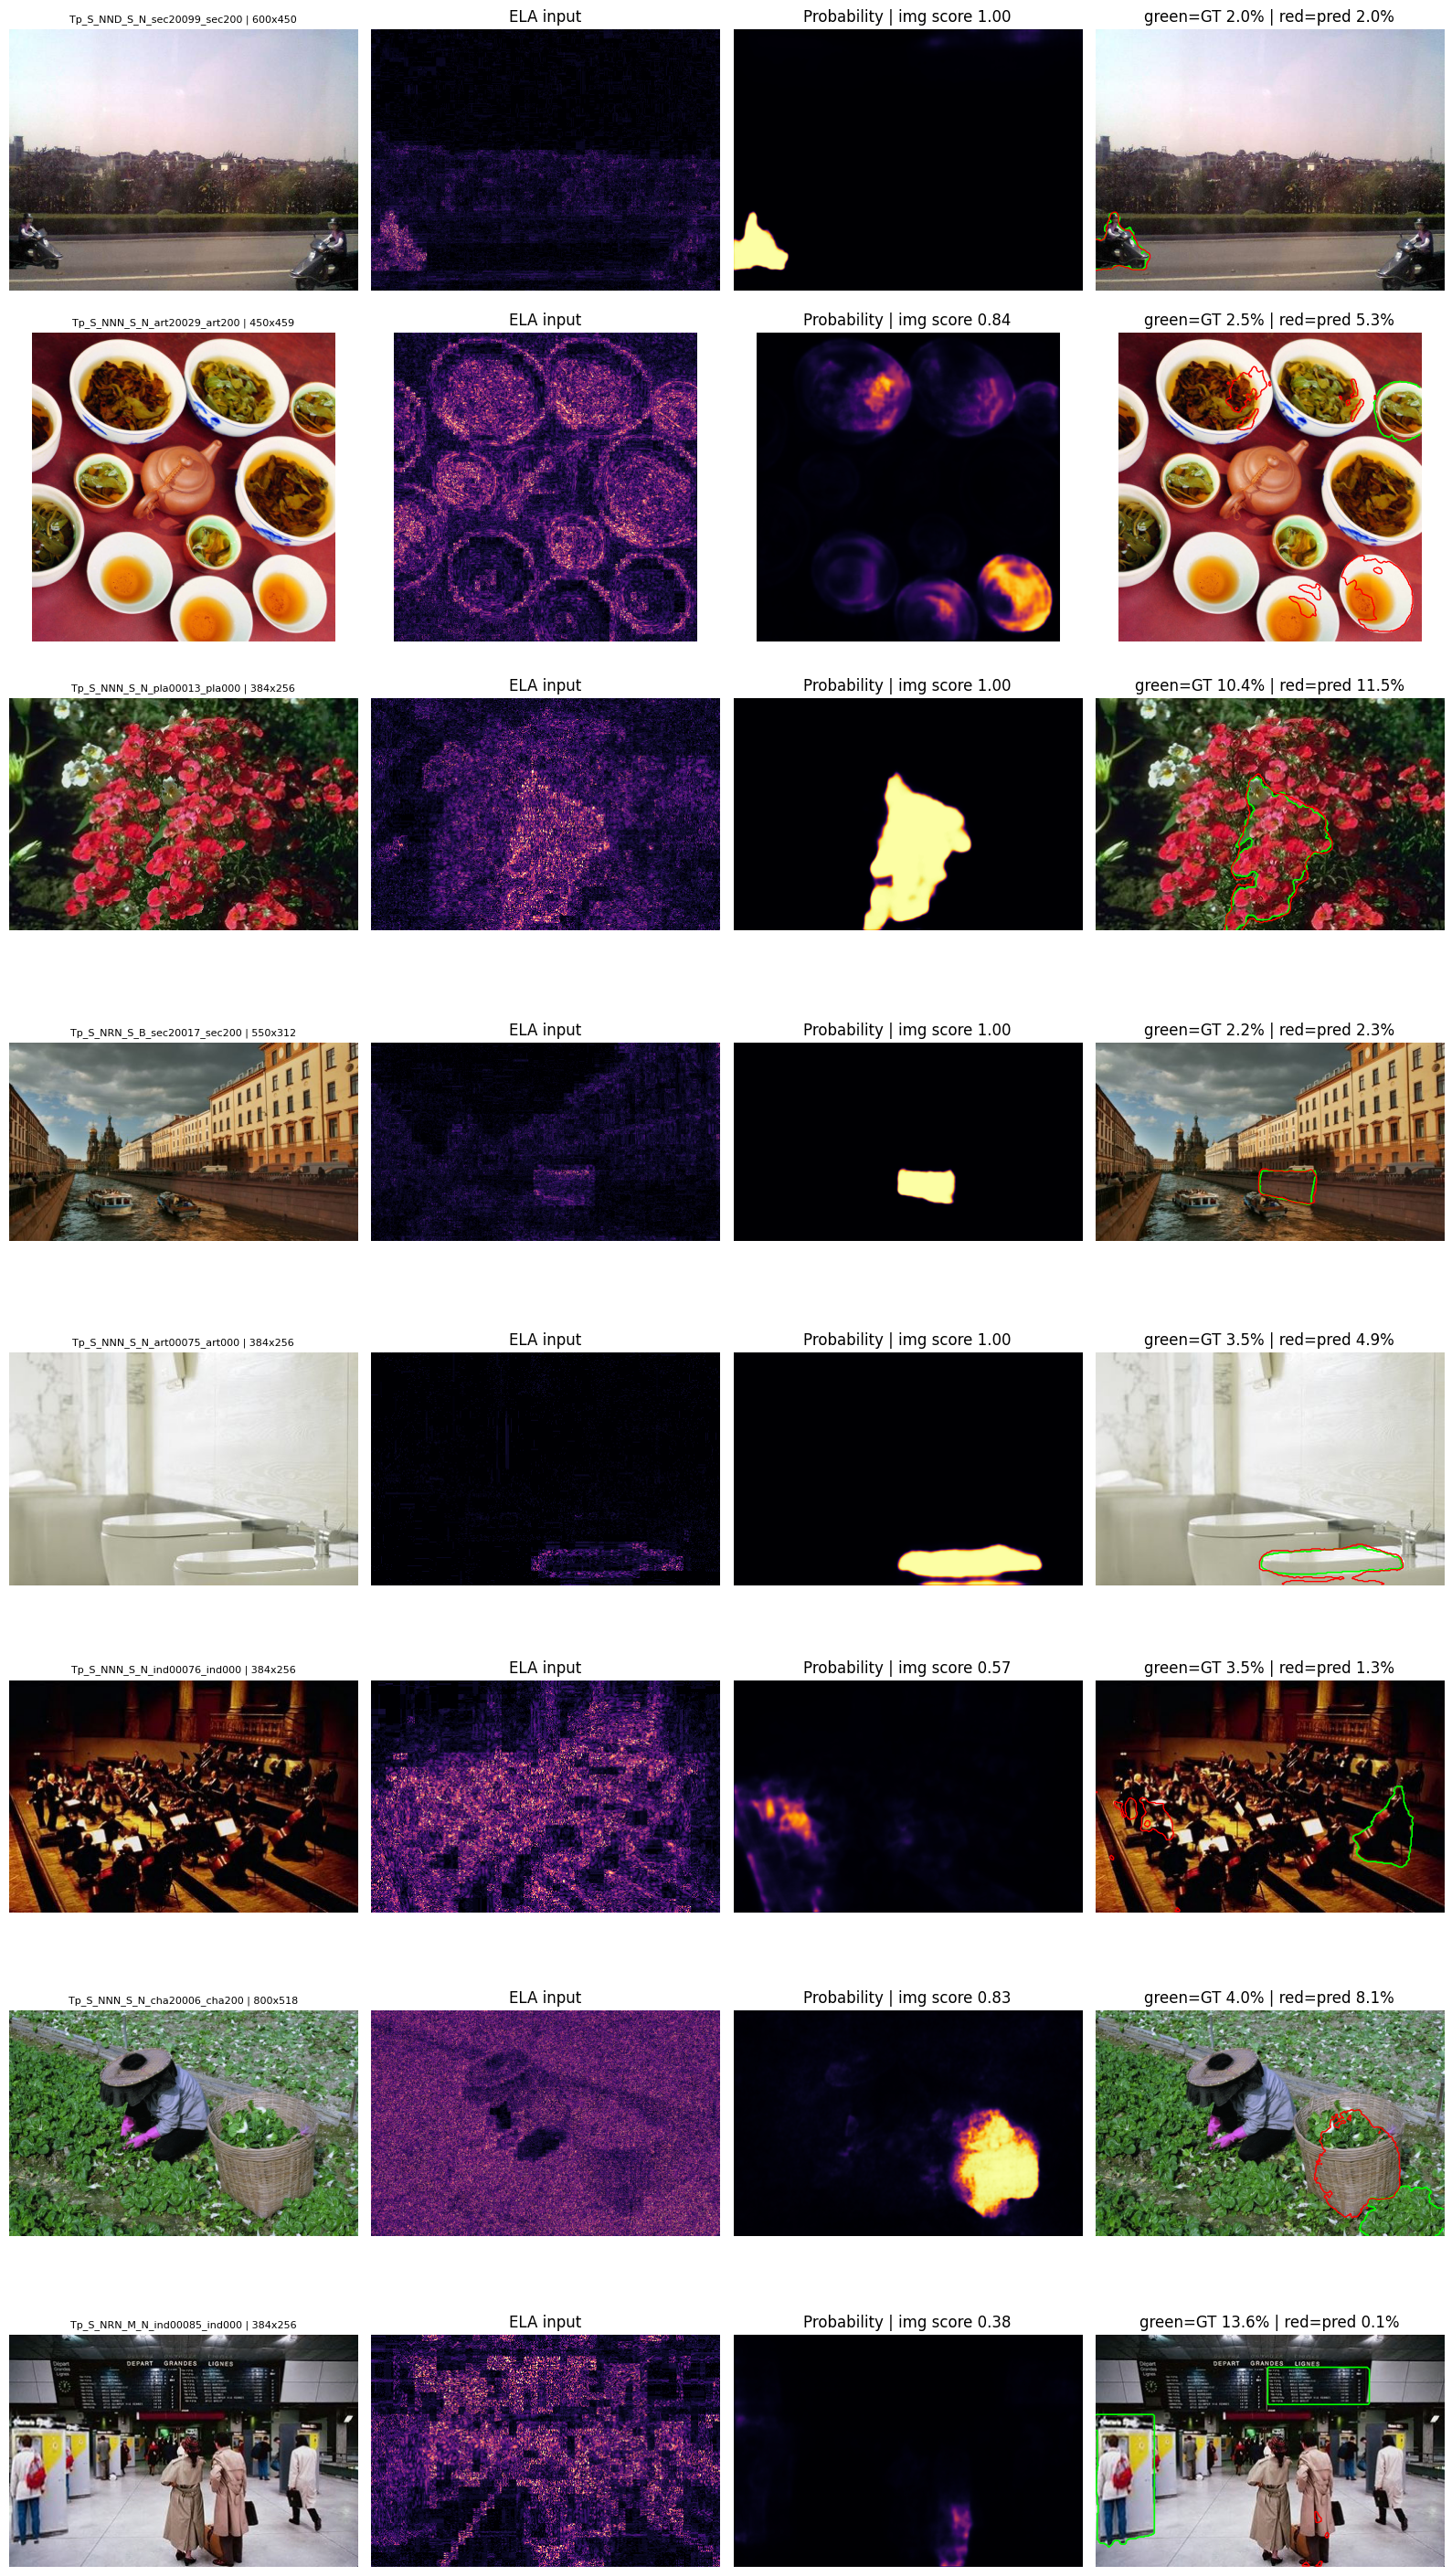

In [18]:
vis = test_pred_df[test_pred_df.true_label == 1].sample(n=8, random_state=SEED + 100)
fig, axes = plt.subplots(len(vis), 4, figsize=(16, 3.6 * len(vis)))
for r, (_, row) in enumerate(vis.iterrows()):
    i = test_res["path"].index(row.image_path)
    im = load_rgb(row.image_path); prob = test_res["prob"][i].astype(np.float32); gt = test_res["mask"][i]
    pred = prob >= PIXEL_THRESHOLD
    _, ela = prepare_image(im)
    axes[r, 0].imshow(im); axes[r, 0].set_title(f"{Path(row.image_path).name[:28]} | {im.size[0]}x{im.size[1]}", fontsize=8)
    axes[r, 1].imshow(ela, cmap="magma"); axes[r, 1].set_title("ELA input")
    axes[r, 2].imshow(prob, cmap="inferno", vmin=0, vmax=1); axes[r, 2].set_title(f"Probability | img score {row.image_score:.2f}")
    axes[r, 3].imshow(im)
    if gt.any(): axes[r, 3].contour(gt.astype(float), levels=[0.5], colors=["lime"], linewidths=1.2)
    if pred.any(): axes[r, 3].contour(pred.astype(float), levels=[0.5], colors=["red"], linewidths=1.0)
    axes[r, 3].set_title(f"green=GT {gt.mean()*100:.1f}% | red=pred {pred.mean()*100:.1f}%")
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.show()


## 14. Counterfactual robustness under benign transformations

Stress test only: does re-saving or resizing the *same* image change the decision or mask? Variants are generated **before** the pipeline's own normalisation, so with `NORMALIZE_FORMAT=True` the JPEG variants are partly absorbed by it (a deliberate robustness effect, not evidence of editing-history recovery).


In [19]:
def predict_pil(image):
    rgb, ela = prepare_image(image)
    prob, c = forward_full(to_tensor4(rgb, ela)[None].to(DEVICE))
    return prob.astype(np.float32), c

def image_score_of(prob, c): return c if IMAGE_SCORE_SOURCE == "cls" else seg_score(prob)

def counterfactual_suite(image):
    image = image.convert("RGB"); w, h = image.size
    restored = image.resize((max(1, int(w * .75)), max(1, int(h * .75))), Image.Resampling.BILINEAR).resize((w, h), Image.Resampling.BILINEAR)
    return {"original": image.copy(), "jpeg_q80": jpeg_roundtrip(image, 80), "jpeg_q55": jpeg_roundtrip(image, 55),
            "resize75_restore": restored, "resize75_then_jpeg70": jpeg_roundtrip(restored, 70)}

def mask_iou(a, b):
    u = np.logical_or(a, b).sum(); return float(np.logical_and(a, b).sum() / u) if u else 1.0

cf_src = pd.concat([test_df[test_df.label == l].sample(n=min(30, int((test_df.label == l).sum())), random_state=SEED + 120 + l) for l in (0, 1)])
cf_rows = []
model.eval()
for k, (_, row) in enumerate(cf_src.iterrows(), start=1):
    outs = {}
    for name, var in counterfactual_suite(load_rgb(row.image_path)).items():
        prob, c = predict_pil(var); s = image_score_of(prob, c)
        outs[name] = (prob >= PIXEL_THRESHOLD, s, int(s >= THRESH_BALANCED))
    base = outs["original"]
    for name, (mk, s, dec) in outs.items():
        cf_rows.append({"true_label": int(row.label), "counterfactual": name, "abs_score_delta": abs(s - base[1]),
                        "decision_changed": int(dec != base[2]), "mask_IoU_vs_original": mask_iou(mk, base[0]),
                        "predicted_area": float(mk.mean())})
    if k % 20 == 0: print(f"{k}/{len(cf_src)}")
cf_df = pd.DataFrame(cf_rows)
cf_summary = cf_df.groupby("counterfactual").agg(mean_abs_score_delta=("abs_score_delta", "mean"),
                                                 decision_flip_rate=("decision_changed", "mean"),
                                                 mean_mask_IoU_vs_original=("mask_IoU_vs_original", "mean"),
                                                 mean_predicted_area=("predicted_area", "mean")).reset_index()
display(cf_summary.round(4))
cf_df.to_csv(OUTPUT_DIR / "counterfactual_per_image.csv", index=False)
cf_summary.to_csv(OUTPUT_DIR / "counterfactual_summary.csv", index=False)


20/60
40/60
60/60


,counterfactual,mean_abs_score_delta,decision_flip_rate,mean_mask_IoU_vs_original,mean_predicted_area
0,jpeg_q55,0.3907,0.5000,0.6000,0.0000
1,jpeg_q80,0.3705,0.4167,0.6000,0.0000
2,original,0.0000,0.0000,1.0000,0.0413
3,resize75_restore,0.2379,0.4000,0.2813,0.0945
4,resize75_then_jpeg70,0.3747,0.4833,0.6007,0.0002


## 15. Single-image analysis and optional Gradio demo


In [20]:
def analyze_pil(image):
    image = image.convert("RGB")
    prob, c = predict_pil(image); s = image_score_of(prob, c)
    pred = prob >= PIXEL_THRESHOLD
    heat = (plt.get_cmap("inferno")(np.clip(prob, 0, 1))[..., :3] * 255).astype(np.float32)
    overlay = Image.fromarray((np.asarray(image, np.float32) * 0.62 + heat * 0.38).clip(0, 255).astype(np.uint8))
    report = {"model": MODEL_DESCRIPTION, "decision": "manipulated_candidate" if s >= THRESH_BALANCED else "authentic_candidate",
              "image_score": round(float(s), 4), "score_source": IMAGE_SCORE_SOURCE,
              "image_threshold_balanced": round(THRESH_BALANCED, 4), "image_threshold_low_fpr": round(THRESH_LOWFPR, 4),
              "pixel_threshold": PIXEL_THRESHOLD, "flagged_area_percent": round(float(pred.mean() * 100), 3),
              "note": "Screening aid only. Not proof of manipulation and not a reconstruction of editing history."}
    return Image.fromarray(pred.astype(np.uint8) * 255), overlay, report

ENABLE_GRADIO = False
if ENABLE_GRADIO:
    import gradio as gr
    demo = gr.Interface(fn=analyze_pil, inputs=gr.Image(type="pil"),
                        outputs=[gr.Image(type="pil", label="Predicted mask"), gr.Image(type="pil", label="Probability overlay"),
                                 gr.JSON(label="Report")], title="TRACE-X v4")
    demo.launch(share=True)
ex_mask, ex_overlay, ex_report = analyze_pil(load_rgb(test_df.iloc[0].image_path))
print(json.dumps(ex_report, indent=2))


{
  "model": "TraceNet (7ch ResNet-18 U-Net, ImageNet-pretrained, ELA=True, SRM=True, normalize_format=True)",
  "decision": "manipulated_candidate",
  "image_score": 0.1586,
  "score_source": "cls",
  "image_threshold_balanced": 0.0604,
  "image_threshold_low_fpr": 0.3528,
  "pixel_threshold": 0.35,
  "flagged_area_percent": 0.336,
  "note": "Screening aid only. Not proof of manipulation and not a reconstruction of editing history."
}


## 16. Export summary


In [21]:
summary = {
    "project": "TRACE-X v4", "model": MODEL_DESCRIPTION, "dataset_slug": CASIA_KAGGLE_SLUG,
    "config": {"crop": CROP_SIZE, "normalize_format": NORMALIZE_FORMAT, "normalize_quality": NORMALIZE_QUALITY,
               "ela_quality": ELA_QUALITY, "use_ela": USE_ELA, "use_srm": USE_SRM, "pos_weight": POS_WEIGHT,
               "epochs_run": len(history_df), "best_epoch": int(best["epoch"]), "samples_per_epoch": SAMPLES_PER_EPOCH},
    "split": {"strategy": "strict source components; largest component in train", "train_rows": len(train_df),
              "val_rows": len(val_df), "test_rows": len(test_df)},
    "image_score_source": IMAGE_SCORE_SOURCE, "test_roc_auc": TEST_AUC,
    "thresholds_selected_on_validation": {"image_balanced": THRESH_BALANCED, "image_low_fpr": THRESH_LOWFPR, "pixel": PIXEL_THRESHOLD},
    "test_image_metrics": img_table.to_dict(orient="records"),
    "test_localization": loc_table.to_dict(orient="index"),
    "v3_vs_v4": cmp_df.to_dict(orient="index"),
    "counterfactual": cf_summary.to_dict(orient="records"),
    "limitations": ["Screening aid, not forensic certification.",
                    "Largest connected source component is training-only, so the held-out population differs from a random sample.",
                    "Single split, single seed, 250 images per class in test: differences of a few points are within noise.",
                    "Format normalisation removes some real compression evidence; compare with NORMALIZE_FORMAT=False.",
                    "Counterfactual tests measure stability only, not editing-history recovery."]}
with open(OUTPUT_DIR / "trace_x_v4_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f" - {p.name:42s} {p.stat().st_size/1024:9.1f} KB")


 - checkpoint_last.pt                          169369.1 KB
 - counterfactual_per_image.csv                    14.0 KB
 - counterfactual_summary.csv                       0.5 KB
 - model_best.pt                               169364.3 KB
 - test_image_metrics.csv                           0.3 KB
 - test_localization_metrics.csv                    0.4 KB
 - test_manifest.csv                              132.1 KB
 - test_predictions.csv                           104.5 KB
 - trace_x_v4_summary.json                          4.5 KB
 - train_manifest.csv                            2064.0 KB
 - training_history.csv                             3.0 KB
 - v3_vs_v4.csv                                     0.3 KB
 - validation_manifest.csv                        135.0 KB
 - validation_pixel_threshold_sweep.csv             1.1 KB


## 17. Interpretation checklist and what to try next

- [ ] Format shortcut accuracy (section 4) and the per-extension table (section 11) were checked.
- [ ] Thresholds came from validation only; test was evaluated once.
- [ ] Report AUC, FPR, **median** IoU and the gated/ungated localization rows together, not just the best one.
- [ ] State that the largest source component is training-only and that this is a single split.

**If results are still weak, test these in order (one change per run):**
1. `NORMALIZE_FORMAT=False` (does format normalisation help or hide real evidence?)
2. `USE_ELA=False`, then `USE_SRM=False` to see which channel matters.
3. `CROP_SIZE=384`, more epochs, or `SAMPLES_PER_EPOCH=9600` if validation is still improving at the time budget.
4. A stronger encoder (ResNet-34/50) or dedicated forensic backbones from the literature (e.g. noise-residual two-stream networks).
5. Repeat with several seeds and group-aware CV folds before making any comparative claim.


In [22]:
import gradio as gr
from scipy import ndimage

DEMO_THRESHOLD = THRESH_LOWFPR   # validation-chosen point: ~10% false-positive rate

def demo_fn(image):
    if image is None:
        return None, None, "Please upload an image."
    image = image.convert("RGB")
    prob, c = predict_pil(image)
    pred = prob >= PIXEL_THRESHOLD
    flagged = c >= DEMO_THRESHOLD

    arr = np.asarray(image, dtype=np.float32)
    heat = plt.get_cmap("inferno")(np.clip(prob, 0, 1))[..., :3] * 255
    a = np.clip(prob, 0, 1)[..., None] * 0.75
    overlay = arr * (1 - a) + heat * a
    if flagged and pred.any():
        edge = pred ^ ndimage.binary_erosion(pred, iterations=2)
        overlay[edge] = [0, 255, 0]
    overlay = Image.fromarray(overlay.clip(0, 255).astype(np.uint8))

    verdict = "🔴 LIKELY MANIPULATED" if flagged else "🟢 LIKELY AUTHENTIC"
    text = (f"## {verdict}\n"
            f"**Manipulation score:** {c:.3f}  (decision threshold {DEMO_THRESHOLD:.3f})\n\n"
            f"**Suspicious area:** {pred.mean()*100:.2f}% of the image\n\n"
            f"*Screening aid only. Not proof of manipulation, and not a reconstruction of editing history.*")
    return image, overlay, text

# Example images from the held-out TEST set (never seen in training)
ex_df = test_pred_df.copy()
good = ex_df[(ex_df.true_label == 1) & (ex_df.IoU_ungated > 0.5)].sample(3, random_state=1).image_path.tolist()
fail = ex_df[(ex_df.true_label == 1) & (ex_df.IoU_ungated == 0)].sample(1, random_state=1).image_path.tolist()
auth = ex_df[(ex_df.true_label == 0) & (ex_df.pred_balanced == 0)].sample(2, random_state=1).image_path.tolist()
examples = [[p] for p in good + fail + auth]

with gr.Blocks(title="TRACE-X") as demo:
    gr.Markdown("# TRACE-X — Image Manipulation Detection & Localization\n"
                "Upload an image. The model scores how likely it is edited and highlights the suspicious region.")
    with gr.Row():
        inp = gr.Image(type="pil", label="Upload image")
        out_img = gr.Image(label="Input (as analysed)")
        out_ov = gr.Image(label="Heatmap + predicted region (green outline)")
    out_txt = gr.Markdown()
    gr.Button("Analyse", variant="primary").click(demo_fn, inp, [out_img, out_ov, out_txt])
    gr.Examples(examples=examples, inputs=inp, label="Held-out test images (3 correct, 1 failure case, 2 authentic)")

demo.launch(share=True, debug=False)

* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://052d67edf193403728.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:

import gradio as gr
import numpy as np
import pandas as pd
import json, io, zipfile, tempfile
from PIL import Image, ImageFilter
from pathlib import Path

def degrade_image(image, jpeg_quality, resize_percent, blur_radius,
                  repeat_count, order):
    image = image.convert("RGB")

    def jpeg(img):
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=int(jpeg_quality))
        buf.seek(0)
        return Image.open(buf).convert("RGB")

    def resize(img):
        w, h = img.size
        scale = max(0.1, float(resize_percent) / 100)
        small = img.resize(
            (max(1, int(w*scale)), max(1, int(h*scale))),
            Image.Resampling.BILINEAR
        )
        return small.resize((w, h), Image.Resampling.BILINEAR)

    def blur(img):
        return img.filter(
            ImageFilter.GaussianBlur(radius=float(blur_radius))
        )

    operations = {
        "JPEG": jpeg,
        "Resize": resize,
        "Blur": blur
    }

    for _ in range(int(repeat_count)):
        for op in order.split(" → "):
            image = operations[op](image)

    return image


def run_survival_lab(image, jpeg_quality, resize_percent,
                     blur_radius, repeat_count, order, threshold):
    if image is None:
        raise gr.Error("Upload an image first.")

    original = image.convert("RGB")
    transformed = degrade_image(
        original, jpeg_quality, resize_percent,
        blur_radius, repeat_count, order
    )

    # Use the real trained model on both images.
    mask1, overlay1, report1 = analyze_pil(original)
    mask2, overlay2, report2 = analyze_pil(transformed)

    score1 = float(report1["image_score"])
    score2 = float(report2["image_score"])

    m1 = np.asarray(mask1.convert("L")) > 0
    m2 = np.asarray(mask2.convert("L")) > 0

    if m1.shape != m2.shape:
        m2 = np.asarray(
            Image.fromarray(m2.astype("uint8") * 255)
            .resize((m1.shape[1], m1.shape[0]), Image.Resampling.NEAREST)
        ) > 0

    union = np.logical_or(m1, m2).sum()
    intersection = np.logical_and(m1, m2).sum()
    mask_overlap = float(intersection / union) if union else 1.0

    decision1 = report1["decision"]
    decision2 = report2["decision"]

    summary = {
        "original": {
            "decision": decision1,
            "manipulation_score": score1,
            "suspicious_area_percent": round(float(m1.mean()*100), 3)
        },
        "transformed": {
            "decision": decision2,
            "manipulation_score": score2,
            "suspicious_area_percent": round(float(m2.mean()*100), 3)
        },
        "evidence_survival": {
            "score_change_transformed_minus_original": round(score2-score1, 5),
            "decision_changed": decision1 != decision2,
            "predicted_mask_iou": round(mask_overlap, 4),
            "suspicious_area_change_percentage_points":
                round(float(m2.mean()*100 - m1.mean()*100), 3)
        },
        "condition": {
            "jpeg_quality": jpeg_quality,
            "resize_percent": resize_percent,
            "blur_radius": blur_radius,
            "repetitions": repeat_count,
            "order": order
        },
        "interpretation":
            "Mask overlap measures prediction stability, not localization accuracy. "
            "Ground-truth masks are required for IoU/Dice accuracy evaluation."
    }

    # Create a downloadable report bundle.
    tmp = tempfile.NamedTemporaryFile(
        suffix=".zip", delete=False
    )
    with zipfile.ZipFile(tmp.name, "w", zipfile.ZIP_DEFLATED) as z:
        z.writestr("report.json", json.dumps(summary, indent=2))
        for name, img in [
            ("original.png", original),
            ("transformed.png", transformed),
            ("original_mask.png", mask1),
            ("transformed_mask.png", mask2),
            ("original_overlay.png", overlay1),
            ("transformed_overlay.png", overlay2)
        ]:
            buf = io.BytesIO()
            img.save(buf, format="PNG")
            z.writestr(name, buf.getvalue())

    return (
        original, transformed,
        overlay1, overlay2,
        mask1, mask2,
        summary, tmp.name
    )


with gr.Blocks(title="SCREEN-TRACE Evidence Survival Lab") as app:
    gr.Markdown("""
    # SCREEN-TRACE — Evidence Survival Lab
    Compare model predictions before and after controlled image degradation.
    **Predictions are screening aids, not proof of manipulation.**
    """)

    with gr.Row():
        source = gr.Image(type="pil", label="Upload source image")
        transformed_view = gr.Image(label="Transformed image")

    with gr.Accordion("Degradation controls", open=True):
        jpeg_quality = gr.Slider(20, 100, value=55, step=5,
                                 label="JPEG quality")
        resize_percent = gr.Slider(25, 100, value=60, step=5,
                                   label="Resize percentage")
        blur_radius = gr.Slider(0, 5, value=1, step=0.5,
                                label="Blur strength")
        repeat_count = gr.Slider(1, 3, value=1, step=1,
                                 label="Number of transformation passes")
        order = gr.Dropdown(
            ["JPEG → Resize → Blur",
             "Resize → JPEG → Blur",
             "Blur → Resize → JPEG"],
            value="JPEG → Resize → Blur",
            label="Transformation order"
        )

    run_btn = gr.Button("Run Evidence Survival Analysis", variant="primary")

    with gr.Row():
        original_overlay = gr.Image(label="Original localization")
        transformed_overlay = gr.Image(label="Transformed localization")

    with gr.Row():
        original_mask = gr.Image(label="Original predicted mask")
        transformed_mask = gr.Image(label="Transformed predicted mask")

    report = gr.JSON(label="Evidence Survival Scorecard")
    download = gr.File(label="Download forensic report ZIP")

    run_btn.click(
        fn=run_survival_lab,
        inputs=[
            source, jpeg_quality, resize_percent,
            blur_radius, repeat_count, order, gr.State(0.5)
        ],
        outputs=[
            gr.State(), transformed_view,
            original_overlay, transformed_overlay,
            original_mask, transformed_mask,
            report, download
        ]
    )

app.launch(share=True)


* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://ead0c7d87cebd524a0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:

# ============================================================
# SCREEN-TRACE — FEATURE C + FEATURE D
# Requires the existing analyze_pil(image) function.
# ============================================================

import io
import numpy as np
import pandas as pd
import gradio as gr
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter


# ------------------------------------------------------------
# 1. CHECK MODEL
# ------------------------------------------------------------

if "analyze_pil" not in globals():
    raise RuntimeError(
        "analyze_pil() is missing. Run your model-loading cell first."
    )


# ------------------------------------------------------------
# 2. IMAGE DEGRADATION FUNCTIONS
# ------------------------------------------------------------

def apply_jpeg(image, quality):
    buffer = io.BytesIO()

    image.convert("RGB").save(
        buffer,
        format="JPEG",
        quality=int(quality)
    )

    buffer.seek(0)

    with Image.open(buffer) as result:
        return result.convert("RGB")


def apply_resize(image, percent):
    image = image.convert("RGB")
    width, height = image.size
    scale = max(0.1, float(percent) / 100)

    small = image.resize(
        (
            max(1, int(width * scale)),
            max(1, int(height * scale))
        ),
        Image.Resampling.BILINEAR
    )

    return small.resize(
        (width, height),
        Image.Resampling.BILINEAR
    )


def apply_blur(image, radius):
    return image.filter(
        ImageFilter.GaussianBlur(radius=float(radius))
    )


def make_degraded_image(
    image, jpeg_quality, resize_percent, blur_radius, order
):
    image = image.convert("RGB")

    operations = {
        "JPEG": lambda x: apply_jpeg(x, jpeg_quality),
        "Resize": lambda x: apply_resize(x, resize_percent),
        "Blur": lambda x: apply_blur(x, blur_radius)
    }

    for operation in order.split(" → "):
        image = operations[operation](image)

    return image


# ------------------------------------------------------------
# 3. RUN MODEL AND STANDARDIZE OUTPUTS
# ------------------------------------------------------------

def analyse_image(image):
    if image is None:
        raise gr.Error("Please upload an image.")

    mask, overlay, report = analyze_pil(image.convert("RGB"))

    if not isinstance(mask, Image.Image):
        mask = Image.fromarray(np.asarray(mask).squeeze())

    if not isinstance(overlay, Image.Image):
        overlay = Image.fromarray(np.asarray(overlay).squeeze())

    mask = mask.convert("L")
    overlay = overlay.convert("RGB")

    score = float(report["image_score"])
    decision = str(report["decision"])

    mask_array = np.asarray(mask) > 0
    suspicious_percent = float(mask_array.mean() * 100)

    return {
        "score": score,
        "decision": decision,
        "mask": mask,
        "mask_array": mask_array,
        "overlay": overlay,
        "suspicious_percent": suspicious_percent
    }


def mask_iou(mask_a, mask_b):
    """
    Measures prediction stability, not localization accuracy.
    """

    a = np.asarray(mask_a.convert("L")) > 0
    b = np.asarray(mask_b.convert("L")) > 0

    if a.shape != b.shape:
        b_image = Image.fromarray(
            b.astype(np.uint8) * 255
        ).resize(
            (a.shape[1], a.shape[0]),
            Image.Resampling.NEAREST
        )

        b = np.asarray(b_image) > 0

    union = np.logical_or(a, b).sum()
    intersection = np.logical_and(a, b).sum()

    return float(intersection / union) if union else 1.0


def create_scorecard_figure(df):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(
        df["Condition"],
        df["Manipulation score"],
        marker="o"
    )
    axes[0].set_title("Manipulation Score")
    axes[0].set_ylabel("Model score")
    axes[0].tick_params(axis="x", rotation=35)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        df["Condition"],
        df["Suspicious area (%)"],
        marker="o"
    )
    axes[1].set_title("Predicted Suspicious Area")
    axes[1].set_ylabel("Percentage of pixels")
    axes[1].tick_params(axis="x", rotation=35)
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    return fig


# ------------------------------------------------------------
# 4. FEATURE C — EVIDENCE SURVIVAL EXPERIMENT
# ------------------------------------------------------------

def run_evidence_survival(
    image, jpeg_quality, resize_percent, blur_radius, order
):
    if image is None:
        raise gr.Error("Upload an image first.")

    original = image.convert("RGB")
    baseline = analyse_image(original)

    conditions = [
        {
            "name": "Original",
            "jpeg": 100,
            "resize": 100,
            "blur": 0,
            "order": "JPEG → Resize → Blur"
        },
        {
            "name": "Mild",
            "jpeg": 85,
            "resize": 90,
            "blur": 0.5,
            "order": "JPEG → Resize → Blur"
        },
        {
            "name": "Moderate",
            "jpeg": 55,
            "resize": 60,
            "blur": 1,
            "order": "JPEG → Resize → Blur"
        },
        {
            "name": "Strong",
            "jpeg": 30,
            "resize": 40,
            "blur": 2,
            "order": "JPEG → Resize → Blur"
        },
        {
            "name": "Blur only",
            "jpeg": 100,
            "resize": 100,
            "blur": 3,
            "order": "JPEG → Resize → Blur"
        },
        {
            "name": "Custom",
            "jpeg": int(jpeg_quality),
            "resize": int(resize_percent),
            "blur": float(blur_radius),
            "order": order
        }
    ]

    rows = []
    previews = []

    for condition in conditions:
        if condition["name"] == "Original":
            transformed = original
            result = baseline
        else:
            transformed = make_degraded_image(
                original,
                condition["jpeg"],
                condition["resize"],
                condition["blur"],
                condition["order"]
            )

            result = analyse_image(transformed)

        rows.append({
            "Condition": condition["name"],
            "JPEG quality": condition["jpeg"],
            "Resize (%)": condition["resize"],
            "Blur radius": condition["blur"],
            "Decision": result["decision"],
            "Manipulation score": round(result["score"], 4),
            "Score change": round(
                result["score"] - baseline["score"], 4
            ),
            "Decision changed": (
                result["decision"] != baseline["decision"]
            ),
            "Suspicious area (%)": round(
                result["suspicious_percent"], 3
            ),
            "Area change (percentage points)": round(
                result["suspicious_percent"]
                - baseline["suspicious_percent"],
                3
            ),
            "Predicted mask IoU vs original": round(
                mask_iou(baseline["mask"], result["mask"]), 4
            )
        })

        previews.append({
            "name": condition["name"],
            "image": transformed,
            "overlay": result["overlay"],
            "mask": result["mask"]
        })

    df = pd.DataFrame(rows)
    fig = create_scorecard_figure(df)

    summary = {
        "original_decision": baseline["decision"],
        "original_score": round(baseline["score"], 4),
        "original_suspicious_area_percent": round(
            baseline["suspicious_percent"], 3
        ),
        "conditions_tested": len(conditions),
        "decision_flips_vs_original": int(
            df["Decision changed"].sum()
        ),
        "interpretation": (
            "Mask IoU measures prediction stability, not accuracy. "
            "Ground-truth masks are needed to evaluate localization accuracy."
        )
    }

    return df, fig, summary, previews


def show_survival(
    image, jpeg_quality, resize_percent, blur_radius, order
):
    df, fig, summary, previews = run_evidence_survival(
        image, jpeg_quality, resize_percent, blur_radius, order
    )

    original = next(
        item for item in previews if item["name"] == "Original"
    )

    custom = next(
        item for item in previews if item["name"] == "Custom"
    )

    comparison = {
        "original": {
            "decision": str(df.iloc[0]["Decision"]),
            "score": float(df.iloc[0]["Manipulation score"]),
            "suspicious_area_percent": float(
                df.iloc[0]["Suspicious area (%)"]
            )
        },
        "custom_transformation": {
            "decision": str(df.iloc[-1]["Decision"]),
            "score": float(df.iloc[-1]["Manipulation score"]),
            "suspicious_area_percent": float(
                df.iloc[-1]["Suspicious area (%)"]
            ),
            "decision_changed": bool(
                df.iloc[-1]["Decision changed"]
            ),
            "mask_iou_vs_original": float(
                df.iloc[-1]["Predicted mask IoU vs original"]
            )
        },
        "interpretation": summary["interpretation"]
    }

    return (
        original["image"],
        custom["image"],
        original["overlay"],
        custom["overlay"],
        df,
        fig,
        comparison
    )


# ------------------------------------------------------------
# 5. FEATURE D — PHYSICAL SCREEN-RECAPTURE CHALLENGE
# ------------------------------------------------------------

def run_screen_recapture(source, phone_photo):

    # Explicitly identify which input is missing.
    if source is None:
        raise gr.Error(
            "Original image is missing. Upload it in the left image box."
        )

    if phone_photo is None:
        raise gr.Error(
            "Phone photograph is missing. Upload it in the right image box."
        )

    # Make independent copies in RGB format.
    source = Image.fromarray(
        np.array(source.convert("RGB"))
    )

    phone_photo = Image.fromarray(
        np.array(phone_photo.convert("RGB"))
    )

    source_result = analyse_image(source)
    photo_result = analyse_image(phone_photo)

    score_difference = (
        photo_result["score"] - source_result["score"]
    )

    area_difference = (
        photo_result["suspicious_percent"]
        - source_result["suspicious_percent"]
    )

    report = {
        "original": {
            "decision": source_result["decision"],
            "manipulation_score": round(
                source_result["score"], 4
            ),
            "suspicious_area_percent": round(
                source_result["suspicious_percent"], 3
            )
        },
        "screen_photo": {
            "decision": photo_result["decision"],
            "manipulation_score": round(
                photo_result["score"], 4
            ),
            "suspicious_area_percent": round(
                photo_result["suspicious_percent"], 3
            )
        },
        "change": {
            "score_photo_minus_original": round(
                score_difference, 4
            ),
            "decision_changed": (
                source_result["decision"]
                != photo_result["decision"]
            ),
            "suspicious_area_change_percentage_points": round(
                area_difference, 3
            )
        },
        "warning": (
            "Images are analysed independently. No pixel-level mask "
            "overlap or localization accuracy is reported because "
            "perspective alignment has not been verified."
        )
    }

    # Return only the four result images and report.
    # Input images are not overwritten by the outputs.
    return (
        source_result["overlay"],
        photo_result["overlay"],
        source_result["mask"],
        photo_result["mask"],
        report
    )


# ------------------------------------------------------------
# 6. GRADIO INTERFACE — FEATURES C AND D
# ------------------------------------------------------------

with gr.Blocks(
    title="SCREEN-TRACE — Evidence Survival Lab"
) as survival_app:

    gr.Markdown("""
    # SCREEN-TRACE — Evidence Survival Lab

    Explore how digital degradation and physical screen recapture
    affect manipulation predictions and localized regions.

    **Screening aid only — model predictions are not proof of manipulation.**
    """)

    # ---------------- FEATURE C ----------------

    with gr.Tab("Feature C — Evidence Survival"):

        source_image = gr.Image(
            type="pil",
            label="Upload original image"
        )

        with gr.Row():
            c_jpeg = gr.Slider(
                20, 100, value=55, step=5,
                label="Custom JPEG quality"
            )

            c_resize = gr.Slider(
                25, 100, value=60, step=5,
                label="Custom resize percentage"
            )

            c_blur = gr.Slider(
                0, 5, value=1, step=0.5,
                label="Custom blur radius"
            )

        c_order = gr.Dropdown(
            choices=[
                "JPEG → Resize → Blur",
                "Resize → JPEG → Blur",
                "Blur → Resize → JPEG"
            ],
            value="JPEG → Resize → Blur",
            label="Custom transformation order"
        )

        run_c = gr.Button(
            "Run Evidence Survival Experiment",
            variant="primary"
        )

        with gr.Row():
            c_original = gr.Image(
                label="Original image"
            )

            c_transformed = gr.Image(
                label="Custom transformed image"
            )

        with gr.Row():
            c_original_overlay = gr.Image(
                label="Original localization overlay"
            )

            c_transformed_overlay = gr.Image(
                label="Transformed localization overlay"
            )

        c_table = gr.Dataframe(
            label="Evidence Survival Scorecard",
            interactive=False
        )

        c_chart = gr.Plot(
            label="Score and suspicious-area changes"
        )

        c_summary = gr.JSON(
            label="Experiment summary"
        )

        run_c.click(
            fn=show_survival,
            inputs=[
                source_image,
                c_jpeg,
                c_resize,
                c_blur,
                c_order
            ],
            outputs=[
                c_original,
                c_transformed,
                c_original_overlay,
                c_transformed_overlay,
                c_table,
                c_chart,
                c_summary
            ]
        )

    # ---------------- FEATURE D ----------------

    with gr.Tab("Feature D — Screen-Recapture Challenge"):

        gr.Markdown("""
        Upload the original source image and the untouched photograph
        of that image displayed on a physical screen.

        The images are analysed independently. Automatic alignment
        is not required, and pixel-level localization accuracy is not claimed.
        """)

        with gr.Row():
            source_photo = gr.Image(
                type="pil",
                label="Original source image"
            )

            recaptured_photo = gr.Image(
                type="pil",
                label="Raw phone photograph"
            )

        run_d = gr.Button(
            "Compare Source and Screen Photograph",
            variant="primary"
        )

        with gr.Row():
            d_source_overlay = gr.Image(
                label="Source localization overlay"
            )

            d_photo_overlay = gr.Image(
                label="Phone-photo localization overlay"
            )

        with gr.Row():
            d_source_mask = gr.Image(
                label="Source predicted mask"
            )

            d_photo_mask = gr.Image(
                label="Phone-photo predicted mask"
            )

        d_report = gr.JSON(
            label="Screen-Recapture Comparison"
        )

        run_d.click(
            fn=run_screen_recapture,
            inputs=[
                source_photo,
                recaptured_photo
            ],
            outputs=[
                d_source_overlay,
                d_photo_overlay,
                d_source_mask,
                d_photo_mask,
                d_report
            ]
        )


# ------------------------------------------------------------
# 7. LAUNCH APP
# ------------------------------------------------------------

survival_app.launch(share=True)


* Running on local URL:  http://127.0.0.1:7865
* Running on public URL: https://3cb18e3415f695f0d7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [26]:

# ============================================================
# SCREEN-TRACE — STANDALONE SCREEN-RECAPTURE LAB
# Features:
# 1. Independent image analysis
# 2. ORB feature matching and perspective alignment
# 3. Alignment quality checks
# 4. Localization mask comparison
# 5. IoU and Dice agreement metrics
# 6. Separate Gradio interface
# ============================================================

import cv2
import numpy as np
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image


# ------------------------------------------------------------
# 1. CHECK REQUIREMENTS
# ------------------------------------------------------------

if "analyze_pil" not in globals():
    raise RuntimeError(
        "Run your existing model-loading cell first. "
        "The function analyze_pil(image) must be available."
    )


# ------------------------------------------------------------
# 2. IMAGE AND MASK HELPERS
# ------------------------------------------------------------

def pil_to_cv(image):
    return cv2.cvtColor(
        np.array(image.convert("RGB")),
        cv2.COLOR_RGB2BGR
    )


def mask_to_array(mask, size):
    """
    Convert a predicted mask to a binary mask matching
    the requested (width, height).
    """
    if isinstance(mask, Image.Image):
        array = np.array(mask.convert("L"))
    else:
        array = np.asarray(mask).squeeze()

    if array.ndim != 2:
        raise ValueError(
            "The model mask must be a 2D image."
        )

    if array.shape != (size[1], size[0]):
        array = cv2.resize(
            array.astype(np.float32),
            size,
            interpolation=cv2.INTER_NEAREST
        )

    return array > 0


def analyse_image(image):
    mask, overlay, report = analyze_pil(
        image.convert("RGB")
    )

    if not isinstance(mask, Image.Image):
        mask = Image.fromarray(
            np.asarray(mask).squeeze()
        )

    if not isinstance(overlay, Image.Image):
        overlay = Image.fromarray(
            np.asarray(overlay).squeeze()
        )

    mask = mask.convert("L")
    overlay = overlay.convert("RGB")

    mask_array = mask_to_array(
        mask,
        image.size
    )

    return {
        "score": float(report["image_score"]),
        "decision": str(report["decision"]),
        "mask": mask,
        "mask_array": mask_array,
        "overlay": overlay,
        "suspicious_area": float(
            mask_array.mean() * 100
        )
    }


# ------------------------------------------------------------
# 3. ORB FEATURE MATCHING AND ALIGNMENT
# ------------------------------------------------------------

def align_screen_photo(source, phone_photo):
    """
    Estimate a homography mapping phone-photo coordinates
    into the original image coordinate system.

    Alignment is accepted only when several quality checks pass.
    These checks are safeguards, not proof of correct alignment.
    """

    source_cv = pil_to_cv(source)
    phone_cv = pil_to_cv(phone_photo)

    source_gray = cv2.cvtColor(
        source_cv, cv2.COLOR_BGR2GRAY
    )

    phone_gray = cv2.cvtColor(
        phone_cv, cv2.COLOR_BGR2GRAY
    )

    orb = cv2.ORB_create(nfeatures=5000)

    kp_source, desc_source = orb.detectAndCompute(
        source_gray, None
    )

    kp_phone, desc_phone = orb.detectAndCompute(
        phone_gray, None
    )

    diagnostics = {
        "source_keypoints": len(kp_source),
        "phone_photo_keypoints": len(kp_phone),
        "good_matches": 0,
        "inliers": 0,
        "inlier_ratio": 0.0,
        "median_reprojection_error_px": None,
        "inlier_coverage_fraction": 0.0,
        "valid_overlap_fraction": 0.0,
        "alignment_accepted": False
    }

    if (
        desc_source is None
        or desc_phone is None
        or len(kp_source) < 4
        or len(kp_phone) < 4
    ):
        diagnostics["reason"] = (
            "Not enough visual features were detected."
        )

        return None, None, diagnostics, None

    matcher = cv2.BFMatcher(
        cv2.NORM_HAMMING
    )

    pairs = matcher.knnMatch(
        desc_phone,
        desc_source,
        k=2
    )

    good_matches = [
        pair[0]
        for pair in pairs
        if len(pair) == 2
        and pair[0].distance < 0.75 * pair[1].distance
    ]

    diagnostics["good_matches"] = len(good_matches)

    match_view = cv2.drawMatches(
        phone_cv,
        kp_phone,
        source_cv,
        kp_source,
        good_matches[:100],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    match_view = cv2.cvtColor(
        match_view, cv2.COLOR_BGR2RGB
    )

    if len(good_matches) < 8:
        diagnostics["reason"] = (
            "Too few reliable feature matches. "
            "Automatic alignment was not attempted."
        )

        return None, None, diagnostics, Image.fromarray(match_view)

    # Map points FROM phone photograph TO original image.
    phone_points = np.float32([
        kp_phone[m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    source_points = np.float32([
        kp_source[m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    H, inlier_mask = cv2.findHomography(
        phone_points,
        source_points,
        cv2.RANSAC,
        4.0
    )

    if H is None or inlier_mask is None:
        diagnostics["reason"] = (
            "Homography estimation failed."
        )

        return None, None, diagnostics, Image.fromarray(match_view)

    inliers = inlier_mask.ravel().astype(bool)
    inlier_count = int(inliers.sum())
    inlier_ratio = inlier_count / len(good_matches)

    diagnostics["inliers"] = inlier_count
    diagnostics["inlier_ratio"] = round(
        inlier_ratio, 4
    )

    # Reprojection error in original-image coordinates.
    projected = cv2.perspectiveTransform(
        phone_points,
        H
    ).reshape(-1, 2)

    target_points = source_points.reshape(-1, 2)

    errors = np.linalg.norm(
        projected[inliers] - target_points[inliers],
        axis=1
    )

    median_error = (
        float(np.median(errors))
        if len(errors) else float("inf")
    )

    diagnostics["median_reprojection_error_px"] = round(
        median_error, 3
    )

    # Measure the spread of inlier points over the original image.
    source_h, source_w = source_gray.shape

    if inlier_count >= 3:
        hull = cv2.convexHull(
            target_points[inliers].astype(np.float32)
        )

        hull_area = cv2.contourArea(hull)

        coverage = hull_area / (
            source_w * source_h
        )
    else:
        coverage = 0.0

    diagnostics["inlier_coverage_fraction"] = round(
        float(coverage), 4
    )

    # Warp phone image into the original image's coordinate system.
    aligned_cv = cv2.warpPerspective(
        phone_cv,
        H,
        (source_w, source_h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )

    # Warp a validity mask to identify actual phone-photo coverage.
    phone_valid = np.ones(
        phone_gray.shape,
        dtype=np.uint8
    ) * 255

    valid_warped = cv2.warpPerspective(
        phone_valid,
        H,
        (source_w, source_h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    ) > 0

    overlap_fraction = float(valid_warped.mean())

    diagnostics["valid_overlap_fraction"] = round(
        overlap_fraction, 4
    )

    # Conservative automatic acceptance checks.
    checks = {
        "at_least_20_inliers": inlier_count >= 20,
        "inlier_ratio_at_least_0.25": inlier_ratio >= 0.25,
        "median_error_at_most_5px": median_error <= 5.0,
        "feature_coverage_at_least_1_percent": coverage >= 0.01,
        "valid_overlap_at_least_35_percent": (
            overlap_fraction >= 0.35
        )
    }

    diagnostics["quality_checks"] = checks

    accepted = all(checks.values())

    diagnostics["alignment_accepted"] = accepted

    if accepted:
        diagnostics["reason"] = (
            "Alignment passed the automatic quality checks. "
            "Inspect the aligned image and feature matches before "
            "trusting localization comparisons."
        )
    else:
        failed = [
            name for name, passed in checks.items()
            if not passed
        ]

        diagnostics["reason"] = (
            "Alignment requires review. Failed checks: "
            + ", ".join(failed)
        )

    aligned_rgb = cv2.cvtColor(
        aligned_cv, cv2.COLOR_BGR2RGB
    )

    return (
        Image.fromarray(aligned_rgb),
        valid_warped,
        diagnostics,
        Image.fromarray(match_view)
    )


# ------------------------------------------------------------
# 4. LOCALIZATION COMPARISON
# ------------------------------------------------------------

def create_mask_comparison(
    original_mask,
    phone_mask,
    valid_overlap
):
    """
    Green = original predicted mask.
    Magenta = aligned phone-photo predicted mask.
    White = overlap between both predictions.

    Metrics are computed only inside valid overlap.
    """

    original_mask = np.asarray(
        original_mask, dtype=bool
    )

    phone_mask = np.asarray(
        phone_mask, dtype=bool
    )

    valid_overlap = np.asarray(
        valid_overlap, dtype=bool
    )

    original_valid = original_mask & valid_overlap
    phone_valid = phone_mask & valid_overlap

    intersection = np.logical_and(
        original_valid,
        phone_valid
    ).sum()

    union = np.logical_or(
        original_valid,
        phone_valid
    ).sum()

    original_count = original_valid.sum()
    phone_count = phone_valid.sum()

    iou = (
        float(intersection / union)
        if union else 1.0
    )

    dice_denominator = (
        original_count + phone_count
    )

    dice = (
        float(2 * intersection / dice_denominator)
        if dice_denominator else 1.0
    )

    # RGB comparison:
    # Green = original only
    # Magenta = phone-photo only
    # White = both masks
    height, width = original_mask.shape

    comparison = np.zeros(
        (height, width, 3),
        dtype=np.uint8
    )

    original_only = (
        original_valid & ~phone_valid
    )

    phone_only = (
        phone_valid & ~original_valid
    )

    both = original_valid & phone_valid

    comparison[original_only] = [0, 255, 0]
    comparison[phone_only] = [255, 0, 255]
    comparison[both] = [255, 255, 255]

    # Outside valid overlap is grey, not treated as disagreement.
    comparison[~valid_overlap] = [80, 80, 80]

    metrics = {
        "mask_iou": round(iou, 4),
        "mask_dice": round(dice, 4),
        "valid_overlap_pixels": int(valid_overlap.sum()),
        "original_suspicious_pixels_in_overlap": int(
            original_count
        ),
        "phone_suspicious_pixels_in_overlap": int(
            phone_count
        ),
        "shared_suspicious_pixels": int(intersection),
        "interpretation": (
            "These metrics measure agreement between predictions "
            "after alignment. They are not localization accuracy."
        )
    }

    return Image.fromarray(comparison), metrics


# ------------------------------------------------------------
# 5. MAIN EXPERIMENT
# ------------------------------------------------------------

def run_screen_lab(source, phone_photo):

    if source is None:
        raise gr.Error(
            "Upload the original digital image."
        )

    if phone_photo is None:
        raise gr.Error(
            "Upload the raw phone photograph."
        )

    source = source.convert("RGB")
    phone_photo = phone_photo.convert("RGB")

    # Always analyse both original inputs independently.
    source_result = analyse_image(source)
    phone_result = analyse_image(phone_photo)

    independent_report = {
        "original": {
            "decision": source_result["decision"],
            "score": round(source_result["score"], 4),
            "suspicious_area_percent": round(
                source_result["suspicious_area"], 3
            )
        },
        "phone_photo": {
            "decision": phone_result["decision"],
            "score": round(phone_result["score"], 4),
            "suspicious_area_percent": round(
                phone_result["suspicious_area"], 3
            )
        },
        "score_change_phone_minus_original": round(
            phone_result["score"] - source_result["score"],
            4
        ),
        "decision_changed": (
            source_result["decision"]
            != phone_result["decision"]
        ),
        "suspicious_area_change_percentage_points": round(
            phone_result["suspicious_area"]
            - source_result["suspicious_area"],
            3
        )
    }

    # Attempt perspective alignment.
    aligned, valid_overlap, diagnostics, match_view = (
        align_screen_photo(source, phone_photo)
    )

    comparison_image = None
    aligned_overlay = None
    metrics = {
        "status": "Not calculated",
        "reason": (
            "Alignment did not pass quality checks. "
            "No mask-overlap metrics are reported."
        )
    }

    # Only calculate agreement metrics when alignment passes.
    if (
        diagnostics["alignment_accepted"]
        and aligned is not None
        and valid_overlap is not None
    ):
        aligned_result = analyse_image(aligned)

        source_mask = mask_to_array(
            source_result["mask"],
            source.size
        )

        aligned_mask = mask_to_array(
            aligned_result["mask"],
            source.size
        )

        comparison_image, metrics = create_mask_comparison(
            source_mask,
            aligned_mask,
            valid_overlap
        )

        aligned_overlay = aligned_result["overlay"]

        # Add aligned-model results to the report.
        diagnostics["aligned_phone_prediction"] = {
            "decision": aligned_result["decision"],
            "score": round(aligned_result["score"], 4),
            "suspicious_area_percent": round(
                aligned_result["suspicious_area"], 3
            )
        }

        metrics["status"] = "Calculated after alignment checks"

    report = {
        "independent_predictions": independent_report,
        "alignment_diagnostics": diagnostics,
        "localization_agreement": metrics,
        "important_note": (
            "Passing numerical checks does not prove correct alignment. "
            "Inspect the match view and aligned image. IoU and Dice "
            "compare model predictions; ground-truth masks are required "
            "to measure localization accuracy."
        )
    }

    return (
        source,
        phone_photo,
        source_result["overlay"],
        phone_result["overlay"],
        aligned,
        match_view,
        aligned_overlay,
        comparison_image,
        report
    )


# ------------------------------------------------------------
# 6. SEPARATE GRADIO APPLICATION
# ------------------------------------------------------------

with gr.Blocks(
    title="SCREEN-TRACE — Screen Recapture Lab"
) as screen_app:

    gr.Markdown("""
    # SCREEN-TRACE — Screen-Recapture Lab

    Compare an original digital image with a photograph of that image
    captured from a physical screen.

    **Alignment and mask agreement are experimental measurements,
    not proof of manipulation or localization accuracy.**
    """)

    with gr.Row():
        input_source = gr.Image(
            type="pil",
            label="Original digital image"
        )

        input_phone = gr.Image(
            type="pil",
            label="Raw phone photograph"
        )

    run_button = gr.Button(
        "Run Screen-Recapture Experiment",
        variant="primary"
    )

    gr.Markdown("## A. Independent model predictions")

    with gr.Row():
        output_source_overlay = gr.Image(
            label="Original localization overlay"
        )

        output_phone_overlay = gr.Image(
            label="Raw phone-photo localization overlay"
        )

    gr.Markdown("## B. Perspective alignment")

    with gr.Row():
        output_aligned = gr.Image(
            label="Aligned phone photograph"
        )

        output_matches = gr.Image(
            label="Feature matches: phone photo → original"
        )

    output_aligned_overlay = gr.Image(
        label="Localization overlay on aligned phone photograph"
    )

    gr.Markdown("""
    ## C. Localization prediction agreement

    Green = original-only prediction  
    Magenta = aligned phone-photo-only prediction  
    White = overlap between predictions  
    Grey = pixels outside the valid phone-photo overlap
    """)

    output_comparison = gr.Image(
        label="Mask agreement visualization"
    )

    output_report = gr.JSON(
        label="Experiment report and alignment diagnostics"
    )

    run_button.click(
        fn=run_screen_lab,
        inputs=[
            input_source,
            input_phone
        ],
        outputs=[
            input_source,
            input_phone,
            output_source_overlay,
            output_phone_overlay,
            output_aligned,
            output_matches,
            output_aligned_overlay,
            output_comparison,
            output_report
        ]
    )


# ------------------------------------------------------------
# 7. LAUNCH THE SEPARATE APP
# ------------------------------------------------------------

screen_app.launch(share=True)


* Running on local URL:  http://127.0.0.1:7866
* Running on public URL: https://c3483a346eae73b539.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [28]:

# ============================================================
# SCREEN-TRACE — ROBUST SCREEN-RECAPTURE LAB
# SIFT/ORB + mutual matching + RANSAC + alignment validation
# ============================================================

import cv2
import numpy as np
import gradio as gr

from PIL import Image


# ------------------------------------------------------------
# 1. CHECK MODEL
# ------------------------------------------------------------

if "analyze_pil" not in globals():
    raise RuntimeError(
        "Run the model-loading cell first. "
        "analyze_pil(image) must be available."
    )


# ------------------------------------------------------------
# 2. IMAGE AND MASK HELPERS
# ------------------------------------------------------------

def pil_to_cv(image):
    return cv2.cvtColor(
        np.array(image.convert("RGB")),
        cv2.COLOR_RGB2BGR
    )


def mask_to_array(mask, size):
    if isinstance(mask, Image.Image):
        arr = np.array(mask.convert("L"))
    else:
        arr = np.asarray(mask).squeeze()

    if arr.ndim != 2:
        raise ValueError("Expected a 2D localization mask.")

    if arr.shape != (size[1], size[0]):
        arr = cv2.resize(
            arr.astype(np.float32),
            size,
            interpolation=cv2.INTER_NEAREST
        )

    return arr > 0


def analyse_image(image):
    mask, overlay, report = analyze_pil(
        image.convert("RGB")
    )

    if not isinstance(mask, Image.Image):
        mask = Image.fromarray(
            np.asarray(mask).squeeze()
        )

    if not isinstance(overlay, Image.Image):
        overlay = Image.fromarray(
            np.asarray(overlay).squeeze()
        )

    mask = mask.convert("L")
    overlay = overlay.convert("RGB")

    binary_mask = mask_to_array(mask, image.size)

    return {
        "score": float(report["image_score"]),
        "decision": str(report["decision"]),
        "mask": mask,
        "binary_mask": binary_mask,
        "overlay": overlay,
        "suspicious_area": float(binary_mask.mean() * 100)
    }


# ------------------------------------------------------------
# 3. FEATURE DETECTION AND MUTUAL MATCHING
# ------------------------------------------------------------

def get_feature_matches(source_gray, phone_gray):

    methods = []

    # Prefer SIFT when available.
    if hasattr(cv2, "SIFT_create"):
        methods.append((
            "SIFT",
            cv2.SIFT_create(nfeatures=6000),
            cv2.NORM_L2,
            0.72
        ))

    # ORB fallback.
    methods.append((
        "ORB",
        cv2.ORB_create(nfeatures=8000),
        cv2.NORM_HAMMING,
        0.78
    ))

    best = None

    for name, detector, norm, ratio in methods:

        kp_s, des_s = detector.detectAndCompute(
            source_gray, None
        )

        kp_p, des_p = detector.detectAndCompute(
            phone_gray, None
        )

        if (
            des_s is None or des_p is None
            or len(kp_s) < 8 or len(kp_p) < 8
        ):
            continue

        matcher = cv2.BFMatcher(norm)

        forward = matcher.knnMatch(des_s, des_p, k=2)
        backward = matcher.knnMatch(des_p, des_s, k=2)

        forward_good = {}

        for pair in forward:
            if (
                len(pair) == 2
                and pair[0].distance < ratio * pair[1].distance
            ):
                forward_good[pair[0].queryIdx] = pair[0].trainIdx

        backward_good = {}

        for pair in backward:
            if (
                len(pair) == 2
                and pair[0].distance < ratio * pair[1].distance
            ):
                backward_good[pair[0].queryIdx] = pair[0].trainIdx

        # Keep matches that agree in both directions.
        mutual = []

        for source_idx, phone_idx in forward_good.items():
            if backward_good.get(phone_idx) == source_idx:
                mutual.append(
                    cv2.DMatch(
                        _queryIdx=source_idx,
                        _trainIdx=phone_idx,
                        _distance=0
                    )
                )

        candidate = {
            "method": name,
            "keypoints_source": kp_s,
            "keypoints_phone": kp_p,
            "matches": mutual
        }

        if best is None or len(mutual) > len(best["matches"]):
            best = candidate

        if name == "SIFT" and len(mutual) >= 20:
            return candidate

    return best


# ------------------------------------------------------------
# 4. GEOMETRY HELPERS
# ------------------------------------------------------------

def hull_coverage(points, width, height):
    if len(points) < 3:
        return 0.0

    points = np.asarray(
        points, dtype=np.float32
    ).reshape(-1, 1, 2)

    hull = cv2.convexHull(points)

    return float(
        cv2.contourArea(hull) / (width * height)
    )


def valid_projected_corners(H, phone_size, source_size):

    phone_w, phone_h = phone_size
    source_w, source_h = source_size

    corners = np.float32([
        [0, 0],
        [phone_w - 1, 0],
        [phone_w - 1, phone_h - 1],
        [0, phone_h - 1]
    ]).reshape(-1, 1, 2)

    try:
        projected = cv2.perspectiveTransform(
            corners, H
        ).reshape(-1, 2)

    except cv2.error:
        return False, 0.0, "Corner transformation failed."

    if not np.isfinite(projected).all():
        return False, 0.0, "Non-finite projected corners."

    contour = projected.astype(
        np.float32
    ).reshape(-1, 1, 2)

    if not cv2.isContourConvex(contour):
        return False, 0.0, "Projected corners are not convex."

    area = abs(cv2.contourArea(contour))
    area_ratio = area / (source_w * source_h)

    if not 0.08 <= area_ratio <= 12.0:
        return (
            False,
            area_ratio,
            "Projected area is implausibly small or large."
        )

    margin_x = source_w * 0.75
    margin_y = source_h * 0.75

    if (
        projected[:, 0].max() < -margin_x
        or projected[:, 0].min() > source_w + margin_x
        or projected[:, 1].max() < -margin_y
        or projected[:, 1].min() > source_h + margin_y
    ):
        return (
            False,
            area_ratio,
            "Projected image lies mostly outside the source canvas."
        )

    return True, area_ratio, "Geometry check passed."


# ------------------------------------------------------------
# 5. ROBUST PERSPECTIVE ALIGNMENT
# ------------------------------------------------------------

def align_screen_photo(source, phone_photo):

    source_rgb = np.array(source.convert("RGB"))
    phone_rgb = np.array(phone_photo.convert("RGB"))

    source_gray = cv2.cvtColor(
        source_rgb, cv2.COLOR_RGB2GRAY
    )

    phone_gray = cv2.cvtColor(
        phone_rgb, cv2.COLOR_RGB2GRAY
    )

    source_h, source_w = source_gray.shape
    phone_h, phone_w = phone_gray.shape

    diagnostics = {
        "method": None,
        "source_keypoints": 0,
        "phone_keypoints": 0,
        "mutual_matches": 0,
        "ransac_inliers": 0,
        "inlier_ratio": 0.0,
        "median_reprojection_error_px": None,
        "source_inlier_coverage": 0.0,
        "phone_inlier_coverage": 0.0,
        "projected_area_ratio": None,
        "valid_overlap_fraction": 0.0,
        "alignment_accepted": False
    }

    features = get_feature_matches(
        source_gray, phone_gray
    )

    if features is None:
        diagnostics["reason"] = (
            "No usable feature descriptors were found."
        )

        return None, None, None, None, diagnostics

    kp_s = features["keypoints_source"]
    kp_p = features["keypoints_phone"]
    matches = features["matches"]

    diagnostics["method"] = features["method"]
    diagnostics["source_keypoints"] = len(kp_s)
    diagnostics["phone_keypoints"] = len(kp_p)
    diagnostics["mutual_matches"] = len(matches)

    # IMPORTANT FIX:
    # Each DMatch has queryIdx = SOURCE keypoint index,
    # and trainIdx = PHONE keypoint index.
    # drawMatches arguments must follow that same order.
    match_array = cv2.drawMatches(
        source_rgb,
        kp_s,
        phone_rgb,
        kp_p,
        matches[:100],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    match_view = Image.fromarray(match_array)

    if len(matches) < 8:
        diagnostics["reason"] = (
            "Fewer than 8 mutual matches. Alignment rejected."
        )

        return None, None, match_view, None, diagnostics

    # Map phone-photo coordinates to source-image coordinates.
    phone_pts = np.float32([
        kp_p[m.trainIdx].pt for m in matches
    ]).reshape(-1, 1, 2)

    source_pts = np.float32([
        kp_s[m.queryIdx].pt for m in matches
    ]).reshape(-1, 1, 2)

    H, inlier_mask = cv2.findHomography(
        phone_pts,
        source_pts,
        cv2.RANSAC,
        4.0,
        maxIters=10000,
        confidence=0.995
    )

    if H is None or inlier_mask is None:
        diagnostics["reason"] = (
            "RANSAC could not estimate a valid homography."
        )

        return None, None, match_view, None, diagnostics

    inliers = inlier_mask.ravel().astype(bool)
    count = int(inliers.sum())
    ratio = count / len(matches)

    diagnostics["ransac_inliers"] = count
    diagnostics["inlier_ratio"] = round(ratio, 4)

    phone_all = phone_pts.reshape(-1, 2)
    source_all = source_pts.reshape(-1, 2)

    phone_inliers = phone_all[inliers]
    source_inliers = source_all[inliers]

    phone_coverage = hull_coverage(
        phone_inliers, phone_w, phone_h
    )

    source_coverage = hull_coverage(
        source_inliers, source_w, source_h
    )

    diagnostics["phone_inlier_coverage"] = round(
        phone_coverage, 4
    )

    diagnostics["source_inlier_coverage"] = round(
        source_coverage, 4
    )

    projected_pts = cv2.perspectiveTransform(
        phone_pts, H
    ).reshape(-1, 2)

    errors = np.linalg.norm(
        projected_pts[inliers] - source_all[inliers],
        axis=1
    )

    median_error = (
        float(np.median(errors))
        if len(errors) else float("inf")
    )

    diagnostics["median_reprojection_error_px"] = round(
        median_error, 3
    )

    geometry_ok, area_ratio, geometry_reason = (
        valid_projected_corners(
            H,
            (phone_w, phone_h),
            (source_w, source_h)
        )
    )

    diagnostics["projected_area_ratio"] = round(
        area_ratio, 4
    )

    # Warp the phone photograph into source coordinates.
    aligned_rgb = cv2.warpPerspective(
        phone_rgb,
        H,
        (source_w, source_h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )

    # Track valid image pixels through the same transform.
    phone_valid = np.ones(
        (phone_h, phone_w), dtype=np.uint8
    ) * 255

    valid_overlap = cv2.warpPerspective(
        phone_valid,
        H,
        (source_w, source_h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    ) > 0

    overlap_fraction = float(valid_overlap.mean())

    diagnostics["valid_overlap_fraction"] = round(
        overlap_fraction, 4
    )

    checks = {
        "at_least_20_inliers": count >= 20,
        "inlier_ratio_at_least_0.30": ratio >= 0.30,
        "median_error_at_most_4px": median_error <= 4.0,
        "source_coverage_at_least_2_percent": (
            source_coverage >= 0.02
        ),
        "phone_coverage_at_least_2_percent": (
            phone_coverage >= 0.02
        ),
        "overlap_at_least_35_percent": (
            overlap_fraction >= 0.35
        ),
        "projected_geometry_valid": geometry_ok
    }

    diagnostics["quality_checks"] = checks
    diagnostics["geometry_reason"] = geometry_reason

    accepted = all(checks.values())
    diagnostics["alignment_accepted"] = accepted

    if accepted:
        diagnostics["reason"] = (
            "Passed automatic alignment checks. "
            "Visual review is still required."
        )
    else:
        failed = [
            name for name, passed in checks.items()
            if not passed
        ]

        diagnostics["reason"] = (
            "Alignment rejected. Failed checks: "
            + ", ".join(failed)
        )

    aligned_image = Image.fromarray(aligned_rgb)

    # Blend the aligned image with the source for manual review.
    blend = cv2.addWeighted(
        source_rgb, 0.5,
        aligned_rgb, 0.5,
        0
    )

    blend[~valid_overlap] = (
        source_rgb[~valid_overlap] // 2
    )

    blend_image = Image.fromarray(blend)

    return (
        aligned_image,
        valid_overlap,
        match_view,
        blend_image,
        diagnostics
    )


# ------------------------------------------------------------
# 6. MASK AGREEMENT
# ------------------------------------------------------------

def compare_masks(source_mask, phone_mask, valid_overlap):

    source_valid = source_mask & valid_overlap
    phone_valid = phone_mask & valid_overlap

    intersection = np.logical_and(
        source_valid, phone_valid
    ).sum()

    union = np.logical_or(
        source_valid, phone_valid
    ).sum()

    count_s = source_valid.sum()
    count_p = phone_valid.sum()

    iou = float(intersection / union) if union else 1.0

    denominator = count_s + count_p

    dice = (
        float(2 * intersection / denominator)
        if denominator else 1.0
    )

    visual = np.zeros(
        (*source_mask.shape, 3),
        dtype=np.uint8
    )

    visual[source_valid & ~phone_valid] = [0, 255, 0]
    visual[phone_valid & ~source_valid] = [255, 0, 255]
    visual[source_valid & phone_valid] = [255, 255, 255]
    visual[~valid_overlap] = [80, 80, 80]

    metrics = {
        "mask_iou": round(iou, 4),
        "mask_dice": round(dice, 4),
        "shared_suspicious_pixels": int(intersection),
        "original_suspicious_pixels_in_overlap": int(count_s),
        "phone_suspicious_pixels_in_overlap": int(count_p),
        "valid_overlap_pixels": int(valid_overlap.sum()),
        "interpretation": (
            "Prediction agreement after alignment; not localization accuracy."
        )
    }

    return Image.fromarray(visual), metrics


# ------------------------------------------------------------
# 7. RUN EXPERIMENT
# ------------------------------------------------------------

def run_screen_lab(source, phone_photo):

    if source is None:
        raise gr.Error("Upload the original digital image.")

    if phone_photo is None:
        raise gr.Error("Upload the raw phone photograph.")

    source = source.convert("RGB")
    phone_photo = phone_photo.convert("RGB")

    # Independent model predictions always run.
    source_result = analyse_image(source)
    phone_result = analyse_image(phone_photo)

    independent = {
        "original": {
            "decision": source_result["decision"],
            "score": round(source_result["score"], 4),
            "suspicious_area_percent": round(
                source_result["suspicious_area"], 3
            )
        },
        "phone_photo": {
            "decision": phone_result["decision"],
            "score": round(phone_result["score"], 4),
            "suspicious_area_percent": round(
                phone_result["suspicious_area"], 3
            )
        },
        "score_change_phone_minus_original": round(
            phone_result["score"] - source_result["score"], 4
        ),
        "decision_changed": (
            source_result["decision"]
            != phone_result["decision"]
        ),
        "suspicious_area_change_percentage_points": round(
            phone_result["suspicious_area"]
            - source_result["suspicious_area"], 3
        )
    }

    (
        aligned,
        valid_overlap,
        match_view,
        blend,
        diagnostics
    ) = align_screen_photo(source, phone_photo)

    aligned_overlay = None
    comparison = None

    metrics = {
        "status": "Not calculated",
        "reason": (
            "Alignment failed automated checks. "
            "Mask agreement metrics were withheld."
        )
    }

    if (
        diagnostics["alignment_accepted"]
        and aligned is not None
        and valid_overlap is not None
    ):
        aligned_result = analyse_image(aligned)

        source_mask = mask_to_array(
            source_result["mask"], source.size
        )

        aligned_mask = mask_to_array(
            aligned_result["mask"], source.size
        )

        comparison, metrics = compare_masks(
            source_mask,
            aligned_mask,
            valid_overlap
        )

        aligned_overlay = aligned_result["overlay"]
        metrics["status"] = "Calculated after alignment checks"

        diagnostics["aligned_phone_prediction"] = {
            "decision": aligned_result["decision"],
            "score": round(aligned_result["score"], 4),
            "suspicious_area_percent": round(
                aligned_result["suspicious_area"], 3
            )
        }

    report = {
        "independent_predictions": independent,
        "alignment_diagnostics": diagnostics,
        "localization_agreement": metrics,
        "caution": (
            "Automatic checks cannot guarantee correct alignment. "
            "Inspect the match view and blend. IoU and Dice measure "
            "prediction agreement, not localization accuracy."
        )
    }

    return (
        source_result["overlay"],
        phone_result["overlay"],
        aligned,
        match_view,
        blend,
        aligned_overlay,
        comparison,
        report
    )


# ------------------------------------------------------------
# 8. SEPARATE GRADIO APPLICATION
# ------------------------------------------------------------

with gr.Blocks(
    title="SCREEN-TRACE — Robust Screen-Recapture Lab"
) as screen_app:

    gr.Markdown("""
    # SCREEN-TRACE — Robust Screen-Recapture Lab

    Robust feature matching, perspective alignment, alignment
    diagnostics and conditional localization prediction agreement.

    **A rejected alignment is preferable to a misleading metric.**
    """)

    with gr.Row():
        input_source = gr.Image(
            type="pil",
            label="Original digital image"
        )

        input_phone = gr.Image(
            type="pil",
            label="Raw phone photograph"
        )

    run_button = gr.Button(
        "Run Screen-Recapture Experiment",
        variant="primary"
    )

    gr.Markdown("## A. Independent model predictions")

    with gr.Row():
        out_source_overlay = gr.Image(
            label="Original localization overlay"
        )

        out_phone_overlay = gr.Image(
            label="Phone-photo localization overlay"
        )

    gr.Markdown("## B. Perspective alignment")

    with gr.Row():
        out_aligned = gr.Image(
            label="Aligned phone photograph"
        )

        out_matches = gr.Image(
            label="Mutual feature matches"
        )

    out_blend = gr.Image(
        label="Blended alignment preview"
    )

    out_aligned_overlay = gr.Image(
        label="Aligned phone-photo localization overlay"
    )

    gr.Markdown("""
    ## C. Localization prediction agreement

    - Green: original-only prediction
    - Magenta: phone-photo-only prediction
    - White: overlapping predictions
    - Grey: outside valid phone-photo coverage

    Metrics are shown only when automated alignment checks pass.
    """)

    out_comparison = gr.Image(
        label="Mask agreement visualization"
    )

    out_report = gr.JSON(
        label="Experiment report and alignment diagnostics"
    )

    run_button.click(
        fn=run_screen_lab,
        inputs=[
            input_source,
            input_phone
        ],
        outputs=[
            out_source_overlay,
            out_phone_overlay,
            out_aligned,
            out_matches,
            out_blend,
            out_aligned_overlay,
            out_comparison,
            out_report
        ]
    )


# ------------------------------------------------------------
# 9. LAUNCH
# ------------------------------------------------------------

screen_app.launch(share=True)


* Running on local URL:  http://127.0.0.1:7868
* Running on public URL: https://f7e20d389c88b6bb0f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
